# [GSE113915](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE113915)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-10-21
> - Modified: 2025-01-12

# 1. Experimental Design

> Uhrf1 regulates active transcriptional marks at bivalent domains in pluripotent stem cells through Setd1a.
> - Kim, KY., Tanaka, Y., Su, J. et al. Uhrf1 regulates active transcriptional marks at bivalent domains in pluripotent stem cells through Setd1a. Nat Commun 9, 2583 (2018). https://doi.org/10.1038/s41467-018-04818-0.
> - polyA RNA-seq
> - Illumina HiSeq 2000, SE100
> - mm10

| Sample | Organism | Cell | Source | Strain | Genotype | Status | Replicate |
| - | - | - | - | - | - | - | - |
| Uhrf1-WT Undiff | Mus musculus | mESC | Embryionic stem cell | E14 | Uhrf1-WT | Undifferentiated | None |
| Uhrf1-WT Diff1W | Mus musculus | mESC | mESC-derived EB      | E14 | Uhrf1-WT | Differentiated at week1 | None |
| Uhrf1-WT Diff2W | Mus musculus | mESC | mESC-derived EB      | E14 | Uhrf1-WT | Differentiated at week2 | None |
| Uhrf1-WT Diff3W | Mus musculus | mESC | mESC-derived EB | E14 | Uhrf1-WT | Differentiated at week3 | None |
| Uhrf1-KO Undiff | Mus musculus | mESC | Embryionic stem cell | E14 | Uhrf1-KO | Undifferentiated | None |
| Uhrf1-KO Diff1W | Mus musculus | mESC | mESC-derived EB | E14 | Uhrf1-KO | Differentiated at week1 | None |
| Uhrf1-KO Diff2W | Mus musculus | mESC | mESC-derived EB | E14 | Uhrf1-KO | Differentiated at week2 | None |
| Uhrf1-KO Diff3W | Mus musculus | mESC | mESC-derived EB      | E14 | Uhrf1-KO | Differentiated at week3 | None |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Uhrf1_GSE113915/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)
head(raw_counts)

[1] 55335    16

,Geneid,Chr,Start,End,Strand,Length,gene_name,gene_type,mESC_Uhrf1_KO_Diff1W,mESC_Uhrf1_KO_Diff2W,mESC_Uhrf1_KO_Diff3W,mESC_Uhrf1_KO_Undiff,mESC_Uhrf1_WT_Diff1W,mESC_Uhrf1_WT_Diff2W,mESC_Uhrf1_WT_Diff3W,mESC_Uhrf1_WT_Undiff
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,ENSMUSG00000102693.1,chr1,3073253,3074322,+,1070,4933401J01Rik,TEC,0,0,0,0,0,0,0,0
2,ENSMUSG00000064842.1,chr1,3102016,3102125,+,110,Gm26206,snRNA,0,0,0,1,0,0,0,1
3,ENSMUSG00000051951.5,chr1;chr1;chr1;chr1;chr1;chr1;chr1,3205901;3206523;3213439;3213609;3214482;3421702;3670552,3207317;3207317;3215632;3216344;3216968;3421901;3671498,-;-;-;-;-;-;-,6094,Xkr4,protein_coding,8,31,57,27,53,62,125,43
4,ENSMUSG00000102851.1,chr1,3252757,3253236,+,480,Gm18956,processed_pseudogene,0,0,0,0,0,0,1,0
5,ENSMUSG00000103377.1,chr1,3365731,3368549,-,2819,Gm37180,TEC,0,0,0,0,0,0,2,2
6,ENSMUSG00000104017.1,chr1,3375556,3377788,-,2233,Gm37363,TEC,0,0,0,1,0,0,0,0


In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("mESC"))) |>
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status) |> relevel("Undiff")) |> 
    arrange(Group, Status) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Status
,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC,Uhrf1,WT,Undiff
WT_Diff1W,mESC,Uhrf1,WT,Diff1W
WT_Diff2W,mESC,Uhrf1,WT,Diff2W
WT_Diff3W,mESC,Uhrf1,WT,Diff3W
KO_Undiff,mESC,Uhrf1,KO,Undiff
KO_Diff1W,mESC,Uhrf1,KO,Diff1W
KO_Diff2W,mESC,Uhrf1,KO,Diff2W
KO_Diff3W,mESC,Uhrf1,KO,Diff3W


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("mESC")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

head(raw_counts)

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000102693.1,0,0,0,0,0,0,0,0
ENSMUSG00000064842.1,1,0,0,0,1,0,0,0
ENSMUSG00000051951.5,43,53,62,125,27,8,31,57
ENSMUSG00000102851.1,0,0,0,1,0,0,0,0
ENSMUSG00000103377.1,2,0,0,2,0,0,0,0
ENSMUSG00000104017.1,0,0,0,0,1,0,0,0


In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): WT_Undiff WT_Diff1W ... KO_Diff2W KO_Diff3W
colData names(4): Cell Gene Group Status

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sampleName = sub("^[^_]+_[^_]+_", "", sampleName),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status) |> relevel("Undiff")) |> 
    arrange(Group, Status) |>
    select("sampleName", "fileName", "Cell", "Gene", "Group", "Status") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Gene,Group,Status
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC_Uhrf1_WT_Undiff.tsv,mESC,Uhrf1,WT,Undiff
WT_Diff1W,mESC_Uhrf1_WT_Diff1W.tsv,mESC,Uhrf1,WT,Diff1W
WT_Diff2W,mESC_Uhrf1_WT_Diff2W.tsv,mESC,Uhrf1,WT,Diff2W
WT_Diff3W,mESC_Uhrf1_WT_Diff3W.tsv,mESC,Uhrf1,WT,Diff3W
KO_Undiff,mESC_Uhrf1_KO_Undiff.tsv,mESC,Uhrf1,KO,Undiff
KO_Diff1W,mESC_Uhrf1_KO_Diff1W.tsv,mESC,Uhrf1,KO,Diff1W
KO_Diff2W,mESC_Uhrf1_KO_Diff2W.tsv,mESC,Uhrf1,KO,Diff2W
KO_Diff3W,mESC_Uhrf1_KO_Diff3W.tsv,mESC,Uhrf1,KO,Diff3W


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): WT_Undiff WT_Diff1W ... KO_Diff2W KO_Diff3W
colData names(4): Cell Gene Group Status

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status) |> relevel("Undiff")) |> 
    arrange(Group, Status) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("^[^_]+_[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Status
,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC,Uhrf1,WT,Undiff
WT_Diff1W,mESC,Uhrf1,WT,Diff1W
WT_Diff2W,mESC,Uhrf1,WT,Diff2W
WT_Diff3W,mESC,Uhrf1,WT,Diff3W
KO_Undiff,mESC,Uhrf1,KO,Undiff
KO_Diff1W,mESC,Uhrf1,KO,Diff1W
KO_Diff2W,mESC,Uhrf1,KO,Diff2W
KO_Diff3W,mESC,Uhrf1,KO,Diff3W


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 8 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): WT_Undiff WT_Diff1W ... KO_Diff2W KO_Diff3W
colData names(4): Cell Gene Group Status

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        names = sub("^[^_]+_[^_]+_", "", names),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status) |> relevel("Undiff")) |> 
    arrange(Group, Status) |>
    select("names", "files", "Cell", "Gene", "Group", "Status") |>
    as.data.frame()

coldata |> dplyr::select(-one_of("files"))

names,Cell,Gene,Group,Status
<chr>,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC,Uhrf1,WT,Undiff
WT_Diff1W,mESC,Uhrf1,WT,Diff1W
WT_Diff2W,mESC,Uhrf1,WT,Diff2W
WT_Diff3W,mESC,Uhrf1,WT,Diff3W
KO_Undiff,mESC,Uhrf1,KO,Undiff
KO_Diff1W,mESC,Uhrf1,KO,Diff1W
KO_Diff2W,mESC,Uhrf1,KO,Diff2W
KO_Diff3W,mESC,Uhrf1,KO,Diff3W


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-13 10:54:31

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene mapping from da

In [20]:
DESeqDataSet(gse, design = ~ Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 8 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(8): WT_Undiff WT_Diff1W ... KO_Diff2W KO_Diff3W
colData names(5): names Cell Gene Group Status

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Status"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        sample = sub("^[^_]+_[^_]+_", "", sample),
        Group = factor(Group, levels = c("WT", "KO")), 
        Status = factor(Status) |> relevel("Undiff")) |> 
    arrange(Group, Status) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Status
,<chr>,<chr>,<fct>,<fct>
WT_Undiff,mESC,Uhrf1,WT,Undiff
WT_Diff1W,mESC,Uhrf1,WT,Diff1W
WT_Diff2W,mESC,Uhrf1,WT,Diff2W
WT_Diff3W,mESC,Uhrf1,WT,Diff3W
KO_Undiff,mESC,Uhrf1,KO,Undiff
KO_Diff1W,mESC,Uhrf1,KO,Diff1W
KO_Diff2W,mESC,Uhrf1,KO,Diff2W
KO_Diff3W,mESC,Uhrf1,KO,Diff3W


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): WT_Undiff WT_Diff1W ... KO_Diff2W KO_Diff3W
colData names(4): Cell Gene Group Status

## 2). Object Construction

### a). SummarizedExperiment

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 8 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): WT_Undiff WT_Diff1W ... KO_Diff2W KO_Diff3W
colData names(4): Cell Gene Group Status

### b). DESeqDataSet

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

dds

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): WT_Undiff WT_Diff1W ... KO_Diff2W KO_Diff3W
colData names(4): Cell Gene Group Status

### c). DGEList

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

lapply(dgel, head)

$counts
                     WT_Undiff WT_Diff1W WT_Diff2W WT_Diff3W KO_Undiff
ENSMUSG00000102693.1         0         0         0         0         0
ENSMUSG00000064842.1         1         0         0         0         1
ENSMUSG00000051951.5        43        53        62       125        27
ENSMUSG00000102851.1         0         0         0         1         0
ENSMUSG00000103377.1         2         0         0         2         0
ENSMUSG00000104017.1         0         0         0         0         1
                     KO_Diff1W KO_Diff2W KO_Diff3W
ENSMUSG00000102693.1         0         0         0
ENSMUSG00000064842.1         0         0         0
ENSMUSG00000051951.5         8        31        57
ENSMUSG00000102851.1         0         0         0
ENSMUSG00000103377.1         0         0         0
ENSMUSG00000104017.1         0         0         0

$samples
          group  lib.size norm.factors Cell  Gene Group Status
WT_Undiff    WT 164985675            1 mESC Uhrf1    WT Undiff
WT_Diff1W    WT  38650997            1 mESC Uhrf1    WT Diff1W
WT_Diff2W    WT  27348253            1 mESC Uhrf1    WT Diff2W
WT_Diff3W    WT  29939185            1 mESC Uhrf1    WT Diff3W
KO_Undiff    KO 170104179            1 mESC Uhrf1    KO Undiff
KO_Diff1W    KO  10797643            1 mESC Uhrf1    KO Diff1W

$genes
                            symbol                 type basepairs
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
ENSMUSG00000104017.1       Gm37363                  TEC      2233

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 1
# keep <- rowSums(counts(dds) >= 10) >= 1

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 25971 
 Remove: 29364 
 Retention rate: 46.93 %


In [29]:
design <- model.matrix(~ group + Status, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 20094 
 Remove: 35241 
 Retention rate: 36.31 %


# 3. Normalization

| Functional group | Method | Normalizes for sequencing depth? | Normalizes for gene length? | Corrects for RNA composition bias? | Application |
| :-: | :-: | :-: | :-: | :-: | :- |
| **Simple Normalization** | CPM (Counts per million) | Yes | No | No | Gene expression comparison (heatmaps, clustering) |
| | FPKM / RPKM (Fragments/Reads per kilobase per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| | TPM (Transcripts per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| **Statistical Normalization** | TMM (Trimmed mean of M‑values, *edgeR*) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| | Median‑of‑ratios (DESeq2 size factors) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| **Variance stabilization** | VST (Variance stabilizing transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |
| | rlog (Regularized log transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |

> - RNA Composition, a small number of genes account for a large number of reads

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) is a widely used method in RNA-seq data analysis to normalize gene expression levels. CPM aims to adjust for differences in sequencing depths across samples and provide relative expression values on a comparable scale by scaling the raw read counts of each gene by a sample-specific sequencing depth (total counts) and multiplying by a scaling factor of one million (to obtain counts per million).
> - Pros:
>    - Relatively simple and intuitive to implement.
>    - Allows for direct comparisons of gene expression levels between samples.
> - Cons:
>    - Does not account for gene length, potentially leading to biases in gene expression estimation.
>    - May be sensitive to extreme values or outliers.

<span style="font-size: 150%">

$$ \text{CPM} = \frac {Count_i} {\sum_{i=1}^{n}(Count_i)} \ *\ 10^6 $$
</span>

In [30]:
cpm <- sweep(assay(eSet), 2, colSums(assay(eSet)), FUN = "/") * 1e6
# cpm <- cpm(dgel, normalized.lib.sizes = FALSE, log = FALSE)
cpm |> head()

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,0.26068055,1.3714808,2.2675963,4.1764299,0.15874628,0.7411365,1.9017505,3.7698684
ENSMUSG00000025900.12,0.02424935,0.3105240,0.3657413,3.5082011,0.02939746,0.5558524,1.0428955,4.3651108
ENSMUSG00000102948.1,0.07881040,0.0000000,0.0000000,0.0000000,0.04703593,0.0000000,0.0000000,0.0000000
ENSMUSG00000025902.13,1.04272220,26.7826908,13.4958556,18.8774632,2.69280725,17.6946338,16.5636337,16.4683727
ENSMUSG00000102269.1,0.77597931,0.6728019,0.6217603,0.3341144,0.54091325,0.4632103,0.3067340,0.7275185
ENSMUSG00000102735.1,0.07881040,0.0258770,0.1097224,0.1002343,0.02939746,0.2779262,0.2453872,0.5291043


### 2). FPKM/RPKM

> The most basic RNA-Seq normalization method is Reads Per Kilobase of transcript per Million mapped reads (RPKM) or its closely related method, Fragments Per Kilobase of transcript per Million mapped reads (FPKM). These techniques normalize for both the length of the gene and the total number of reads (i.e., the library size), making expression level comparisons between genes in the same sample possible.
> - Pros:
>    - Widely used and established/incorporated in several software tools.
>    - Makes it possible to compare gene expression levels within the same sample and between different samples.
> - Cons:
>    - Assumes that the total number of reads is the same across all samples, which isn't always accurate, particularly when comparing different conditions or tissues.
>    - Can be biased by highly expressed genes or transcripts, making it less reliable for datasets with a high level of expression variation.
>    - It cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{FPKM} = \frac{Count_i}{\left(\frac{Length_i}{10^3}\right) \times \left(\frac{\sum_{i=1}^{n}(Count_i)}{10^6}\right)} = \frac{Count_i}{{Length_i} \times {\sum_{i=1}^{n}(Count_i)}} \times 10^9 $$
</span>

In [31]:
fpkm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(assay(eSet)) / 1e6, FUN = "/")
# fpkm <- fpkm(dds, robust = FALSE)
# fpkm <- rpkm(
#     dgel, gene.length = "basepairs", 
#     normalized.lib.sizes = FALSE)
fpkm |> head()

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,0.042776592,0.22505428,0.3721031,0.6853347,0.026049603,0.12161741,0.31206934,0.6186197
ENSMUSG00000025900.12,0.001969731,0.02522329,0.0297085,0.2849648,0.002387902,0.04515087,0.08471249,0.3545700
ENSMUSG00000102948.1,0.042212318,0.00000000,0.0000000,0.0000000,0.025193323,0.00000000,0.00000000,0.0000000
ENSMUSG00000025902.13,0.218508423,5.61246665,2.8281340,3.9558808,0.564293220,3.70801211,3.47100455,3.4510421
ENSMUSG00000102269.1,0.259438084,0.22494212,0.2078771,0.1117066,0.180846956,0.15486804,0.10255231,0.2432359
ENSMUSG00000102735.1,0.084199144,0.02764636,0.1172248,0.1070879,0.031407542,0.29692969,0.26216578,0.5652824


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This allows for a more accurate comparison of gene expression between samples.
> - Pros:
>    - More accurate than RPKM/FPKM for comparing gene expression levels between samples.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [32]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
# tpm <- sweep(fpkm, 2, colSums(fpkm), FUN = "/") * 1e6
tpm |> head()

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,0.149581612,0.84817364,1.4301551,2.6374410,0.086619428,0.4695858,1.1835960,2.3527752
ENSMUSG00000025900.12,0.006887774,0.09506032,0.1141828,1.0966579,0.007940186,0.1743353,0.3212919,1.3485239
ENSMUSG00000102948.1,0.147608456,0.00000000,0.0000000,0.0000000,0.083772151,0.0000000,0.0000000,0.0000000
ENSMUSG00000025902.13,0.764082434,21.15199156,10.8697573,15.2238045,1.876372412,14.3172738,13.1645974,13.1252306
ENSMUSG00000102269.1,0.907205679,0.84775095,0.7989626,0.4298914,0.601347362,0.5979722,0.3889536,0.9250907
ENSMUSG00000102735.1,0.294428405,0.10419227,0.4505462,0.4121171,0.104435500,1.1464967,0.9943251,2.1499193


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [33]:
dds <- estimateSizeFactors(dds)
# Calculation of count expression matrix adjusted by normalization factor using the DESeq2 method.
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)
norm_fpkm |> head()

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,10.688822,48.8800727,78.724099,129.161063,6.913127,24.957824,60.333089,114.41841
ENSMUSG00000025900.12,0.994309,11.0671863,12.697435,108.495293,1.280209,18.718368,33.085887,132.48447
ENSMUSG00000102948.1,3.231504,0.0000000,0.000000,0.000000,2.048334,0.000000,0.000000,0.00000
ENSMUSG00000025902.13,42.755286,954.5448151,468.535366,583.808003,117.267111,595.868057,525.481742,499.82779
ENSMUSG00000102269.1,31.817887,23.9789036,21.585640,10.332885,23.555839,15.598640,9.731143,22.08075
ENSMUSG00000102735.1,3.231504,0.9222655,3.809231,3.099866,1.280209,9.359184,7.784915,16.05872


,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,0.04982005,0.22782753,0.3669290,0.60201314,0.032221731,0.11632715,0.28120946,0.5332984
ENSMUSG00000025900.12,0.00229406,0.02553411,0.0292954,0.25031932,0.002953685,0.04318684,0.07633545,0.3056669
ENSMUSG00000102948.1,0.04916287,0.00000000,0.0000000,0.00000000,0.031162567,0.00000000,0.00000000,0.0000000
ENSMUSG00000025902.13,0.25448735,5.68162670,2.7888089,3.47493286,0.697995463,3.54671652,3.12776420,2.9750671
ENSMUSG00000102269.1,0.30215636,0.22771399,0.2049865,0.09812552,0.223696388,0.14813140,0.09241113,0.2096883
ENSMUSG00000102735.1,0.09806311,0.02798704,0.1155948,0.09406841,0.038849167,0.28401348,0.23624075,0.4873175


### 2). edgeR' TMM

> Trimmed Mean of M-values (TMM) normalization, implemented in edgeR, calculates scaling factors based on a weighted trimmed mean of the log-expression ratios. This method is robust against high-count genes and differences in RNA composition.
> - Pros:
>    - Deals well with datasets containing different RNA compositions.
>    - Suitable for datasets with a few highly expressed genes or when comparing different conditions or tissues.
> - Cons:
>    - Like DESeq, it assumes that most genes are not differentially expressed, which may not always hold.
>    - Susceptible to the influence of extreme expression values or outliers.

**edgeR-normalized counts: Trimmed Mean of M-values (TMM) normalization Method**

> 1. For gene 𝑖, first calculate the M-value (logarithmic fold change) and A-value (average expression) between sample 𝑗 and reference sample 𝑟:

<span style="font-size: 150%">

$$ M_i = \log_2 \left( \frac{\frac{\text{counts}_{ij}}{N_j}}{\frac{\text{counts}_{ir}}{N_r}} \right) $$
$$ A_i = \frac{1}{2} \log_2 \left( \frac{\text{counts}_{ij}}{N_j} \times \frac{\text{counts}_{ir}}{N_r} \right) $$
</span>

> 2. Deradicalize

> 3. Weighted average


<span style="font-size: 150%">

$$ \text{TMM}_j = \exp \left( \frac{\sum_{i \in S} w_i M_i}{\sum_{i \in S} w_i} \right) $$
$$ w_i = \frac{N_j - \frac{\text{counts}_{ij}}{N_j}}{N_j} + \frac{N_r - \frac{\text{counts}_{ir}}{N_r}}{N_r} $$
</span>

> 4. Calculate the normalization factor for sample 𝑗:

<span style="font-size: 150%">

$$ \frac{1}{\text{TMM}_j} $$
</span>

In [34]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(
    dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# Calculation of rpkm expression matrix adjusted by normalization factor using the TMM method.
norm_fpkm <- rpkm(
    dgel, gene.length = "basepairs",
    normalized.lib.sizes = TRUE)
norm_fpkm |> head()

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,0.31358841,1.3587653,2.2141219,3.7582203,0.1980688,0.7033720,1.7385454,3.3410380
ENSMUSG00000025900.12,0.02917101,0.3076450,0.3571164,3.1569050,0.0366794,0.5275290,0.9533959,3.8685703
ENSMUSG00000025902.13,1.25435362,26.5343784,13.1775964,16.9871556,3.3598331,16.7930056,15.1421696,14.5950606
ENSMUSG00000102269.1,0.93347246,0.6665641,0.6070979,0.3006576,0.6749010,0.4396075,0.2804105,0.6447617
ENSMUSG00000098104.1,1.30540290,1.0511203,0.3928281,0.7215783,0.9316568,0.9671364,0.5047390,1.4067528
ENSMUSG00000103922.1,3.82140289,2.4355227,1.6427356,1.7137484,3.5579019,2.5497234,1.9067917,2.1687439


,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,0.051458550,0.22296772,0.36332817,0.6167083,0.032502259,0.11542041,0.28528805,0.5482504
ENSMUSG00000025900.12,0.002369508,0.02498944,0.02900791,0.2564296,0.002979401,0.04285021,0.07744260,0.3142369
ENSMUSG00000025902.13,0.262857004,5.56043135,2.76144099,3.5597560,0.704072327,3.51907074,3.17312859,3.0584787
ENSMUSG00000102269.1,0.312093769,0.22285660,0.20297490,0.1005208,0.225643926,0.14697676,0.09375144,0.2155673
ENSMUSG00000098104.1,0.888029181,0.71504783,0.26722998,0.4908696,0.633780129,0.65791595,0.34335986,0.9569747
ENSMUSG00000103922.1,3.574745456,2.27831867,1.53670308,1.6031323,3.328252490,2.38514814,1.78371537,2.0287595


### 3). limma's voom

> Quantile normalization, used in Limma-Voom (mean-variance modeling at the observational level), transforms the data so that the distribution of gene expression is the same across all samples. It’s particularly useful when comparing many samples.
> - Pros:
>    - Reduces technical variation and is suitable for datasets with complex experimental designs.
>    - Can account for unwanted variation due to hidden confounding factors.
> - Cons:
>    - Assumes that the observed differences in gene expression between samples are due to technical factors, which could ignore biological variation.
>    - Does not account for library size or sequencing depth differences.

In [35]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)
norm_v$E |> head()

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,-1.65637715,0.45584274,1.1583226,1.9158088,-2.30945450,-0.42017755,0.82096428,1.7528963
ENSMUSG00000025900.12,-4.92939564,-1.64176805,-1.4151443,1.6653645,-4.63138259,-0.80720068,-0.02703263,1.9626887
ENSMUSG00000025902.13,0.33113191,4.73048760,3.7219688,4.0876485,1.74996371,4.07356019,3.92316914,3.8703023
ENSMUSG00000102269.1,-0.09369609,-0.55770379,-0.6781787,-1.6634173,-0.55943275,-1.04820878,-1.69688403,-0.5690318
ENSMUSG00000098104.1,0.38851939,0.08941519,-1.2838998,-0.4410249,-0.09646077,0.01592156,-0.90838813,0.5221161
ENSMUSG00000103922.1,1.93547832,1.29180459,0.7316971,0.7897553,1.83251328,1.37500265,0.95220881,1.1362250


## Variance Stabilization

> Transformation for visualization

### 1). rlog

> Regularized-logarithm transformation: the rlog tends to work well on small datasets (n < 30)

In [36]:
rld <- rlog(dds, blind = FALSE)
assay(rld) |> head()

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,4.1603371,5.5453288,6.0299538,6.5567203,3.8286607,4.9209353,5.754393,6.4218109
ENSMUSG00000025900.12,2.0886960,3.7154139,3.8392696,6.0207777,2.2004503,4.1895775,4.744062,6.2357369
ENSMUSG00000102948.1,-0.0924463,-0.6606022,-0.6545322,-0.6586746,-0.2612507,-0.5338846,-0.597213,-0.5930635
ENSMUSG00000025902.13,6.5035363,9.5461297,8.7707580,9.0068107,7.3777044,9.0279643,8.893102,8.8394864
ENSMUSG00000102269.1,4.7130855,4.4482478,4.3534722,3.7492527,4.4346387,4.0832120,3.721323,4.3715589
ENSMUSG00000102735.1,1.9690873,1.5147027,2.0686755,1.9591911,1.5574445,2.6170166,2.505604,3.0624254


### 2). VST

> Variance stabilizing transformation: the VST is much faster to compute and is less sensitive to high count outliers than the rlog.

In [37]:
vsd <- vst(dds, blind = FALSE)
assay(vsd) |> head()

,WT_Undiff,WT_Diff1W,WT_Diff2W,WT_Diff3W,KO_Undiff,KO_Diff1W,KO_Diff2W,KO_Diff3W
ENSMUSG00000051951.5,4.622020,6.013218,6.566528,7.184653,4.338097,5.321744,6.251883,7.029895
ENSMUSG00000025900.12,3.564449,4.646837,4.748079,6.962678,3.630204,5.062100,5.597838,7.217346
ENSMUSG00000102948.1,3.951556,3.070531,3.070531,3.070531,3.775869,3.070531,3.070531,3.070531
ENSMUSG00000025902.13,5.866596,9.923734,8.922411,9.230002,7.061131,9.258694,9.082557,9.012604
ENSMUSG00000102269.1,5.558324,5.284275,5.187893,4.598172,5.267746,4.909384,4.556674,5.208425
ENSMUSG00000102735.1,3.951556,3.546386,4.024531,3.933952,3.630204,4.530230,4.410633,4.933114


## Summary

In [38]:
suppressPackageStartupMessages(library(vsn))

In [39]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [40]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](CPM+1))) + 
    common_theme
p3 <- meanSdPlot(log2(fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](FPKM+1))) + 
    common_theme
p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p5 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p6 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


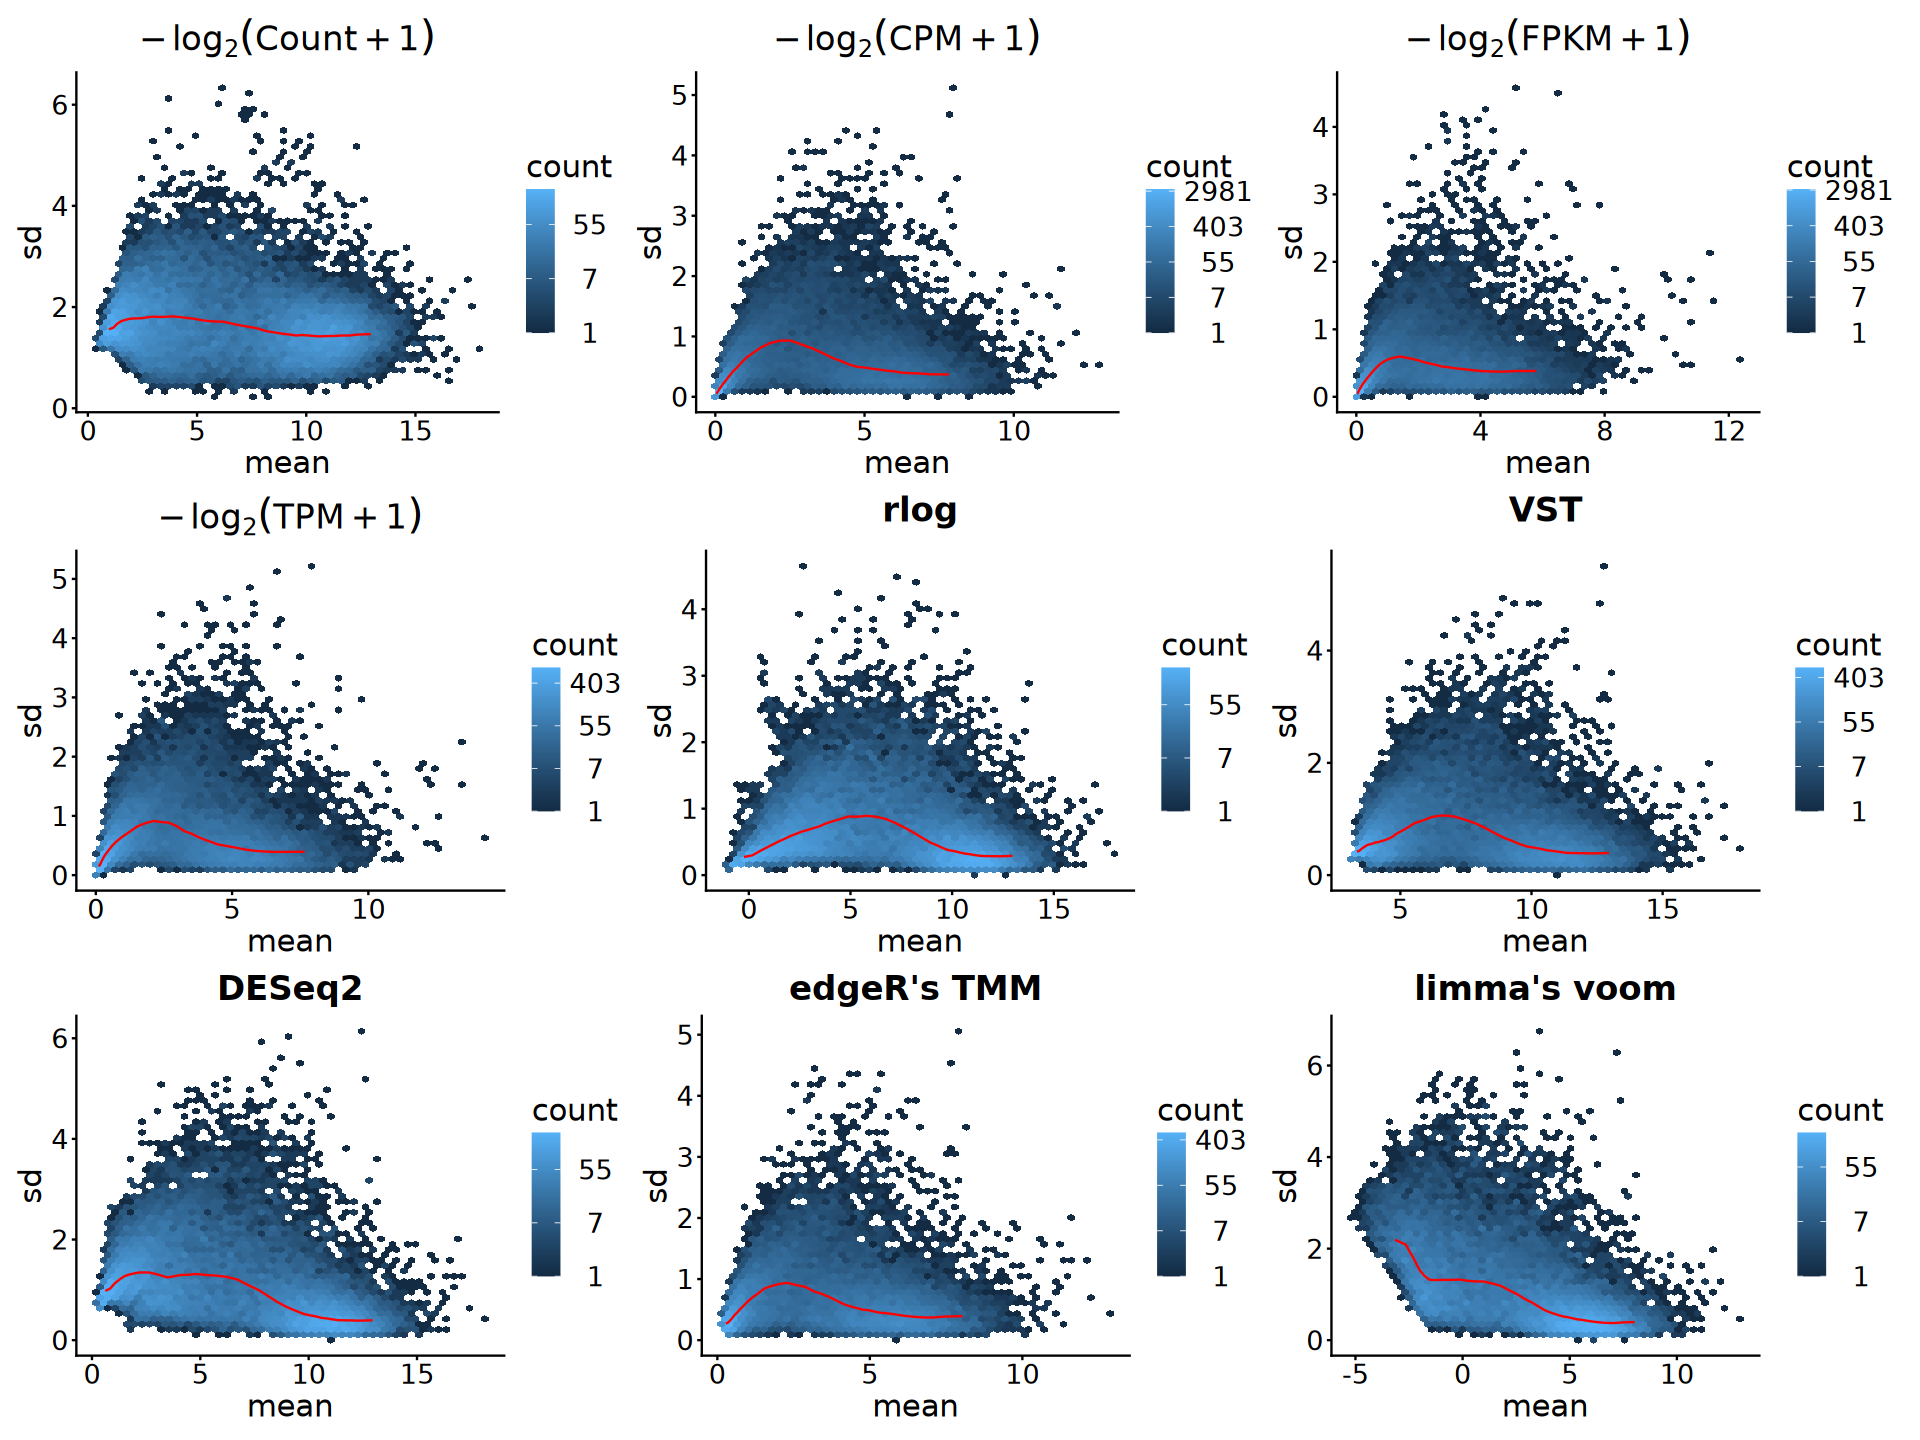

In [41]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6) / (p7 + p8 + p9)

# 4. Exploration

In [42]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [43]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Status) |> 
    rownames_to_column(var = "Sample") |>
    mutate(
        librarySize = colSums(assay(eSet))[Sample], 
        Sample = gsub("_", "\n", Sample), 
        Sample = factor(Sample, levels = Sample))

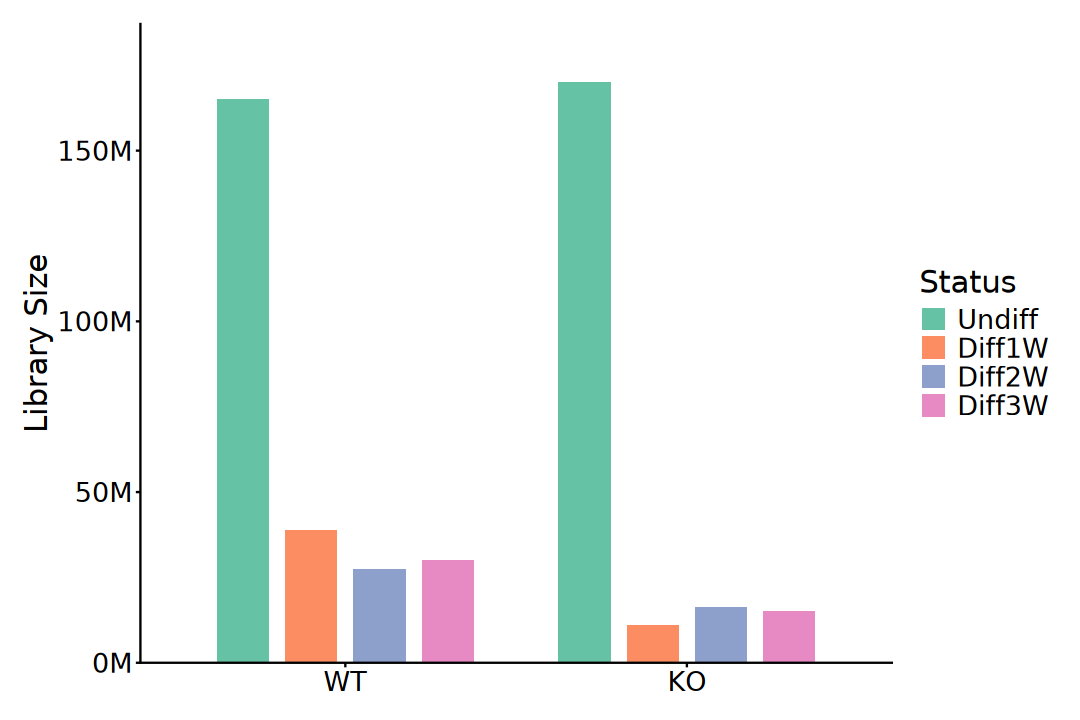

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Status)) +
    geom_bar(
        aes(fill = Status), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [45]:
# remotes::install_github("psyteachr/introdataviz")
suppressPackageStartupMessages(library(introdataviz))

Warning message:
"Using the `size` aesthetic with geom_polygon was deprecated in ggplot2 3.4.0.
ℹ Please use the `linewidth` aesthetic instead."


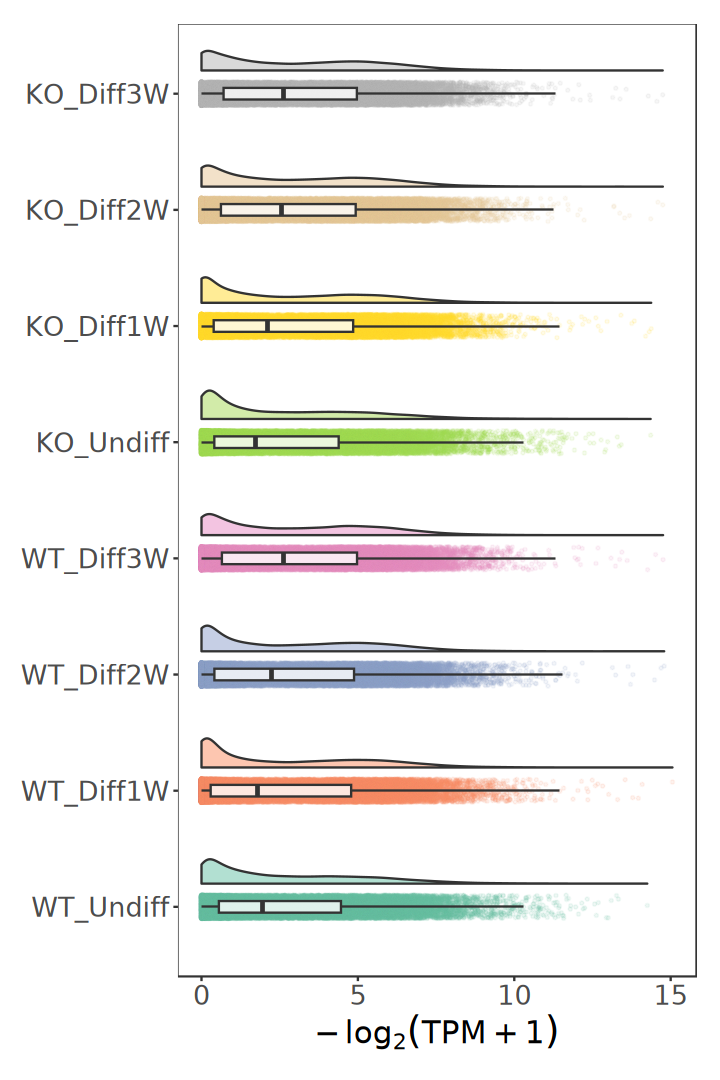

In [46]:
options(repr.plot.width = 6, repr.plot.height = 9)

norm_mat |> as.data.frame() |> 
    pivot_longer(
        cols = everything(), names_to = "Sample", 
        values_to = "Value") |>
    mutate(
        Sample = factor(Sample, levels = colnames(norm_mat))) |>
    ggplot(aes(x = Sample, y = Value)) +
        geom_flat_violin(
            aes(fill = Sample), width = 0.5, alpha = 0.5,
            position = position_nudge(x = 0.2, y = 0)) +
        geom_point(
            aes(color = Sample), size = 0.5, alpha = 0.1,
            position = position_jitter(width = 0.1)) + 
        geom_boxplot(
            width = 0.1, alpha = 0.8, outlier.shape = NA) +
        scale_fill_brewer(palette = "Set2") +
        scale_colour_brewer(palette = "Set2") +
        coord_flip() +
        labs(x = NULL, y = expression(-log[2](TPM+1))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.position = "none",
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

## 2). PCA

In [47]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [48]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [49]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Status), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [50]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Status"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [51]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Status), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [52]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [53]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Status), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

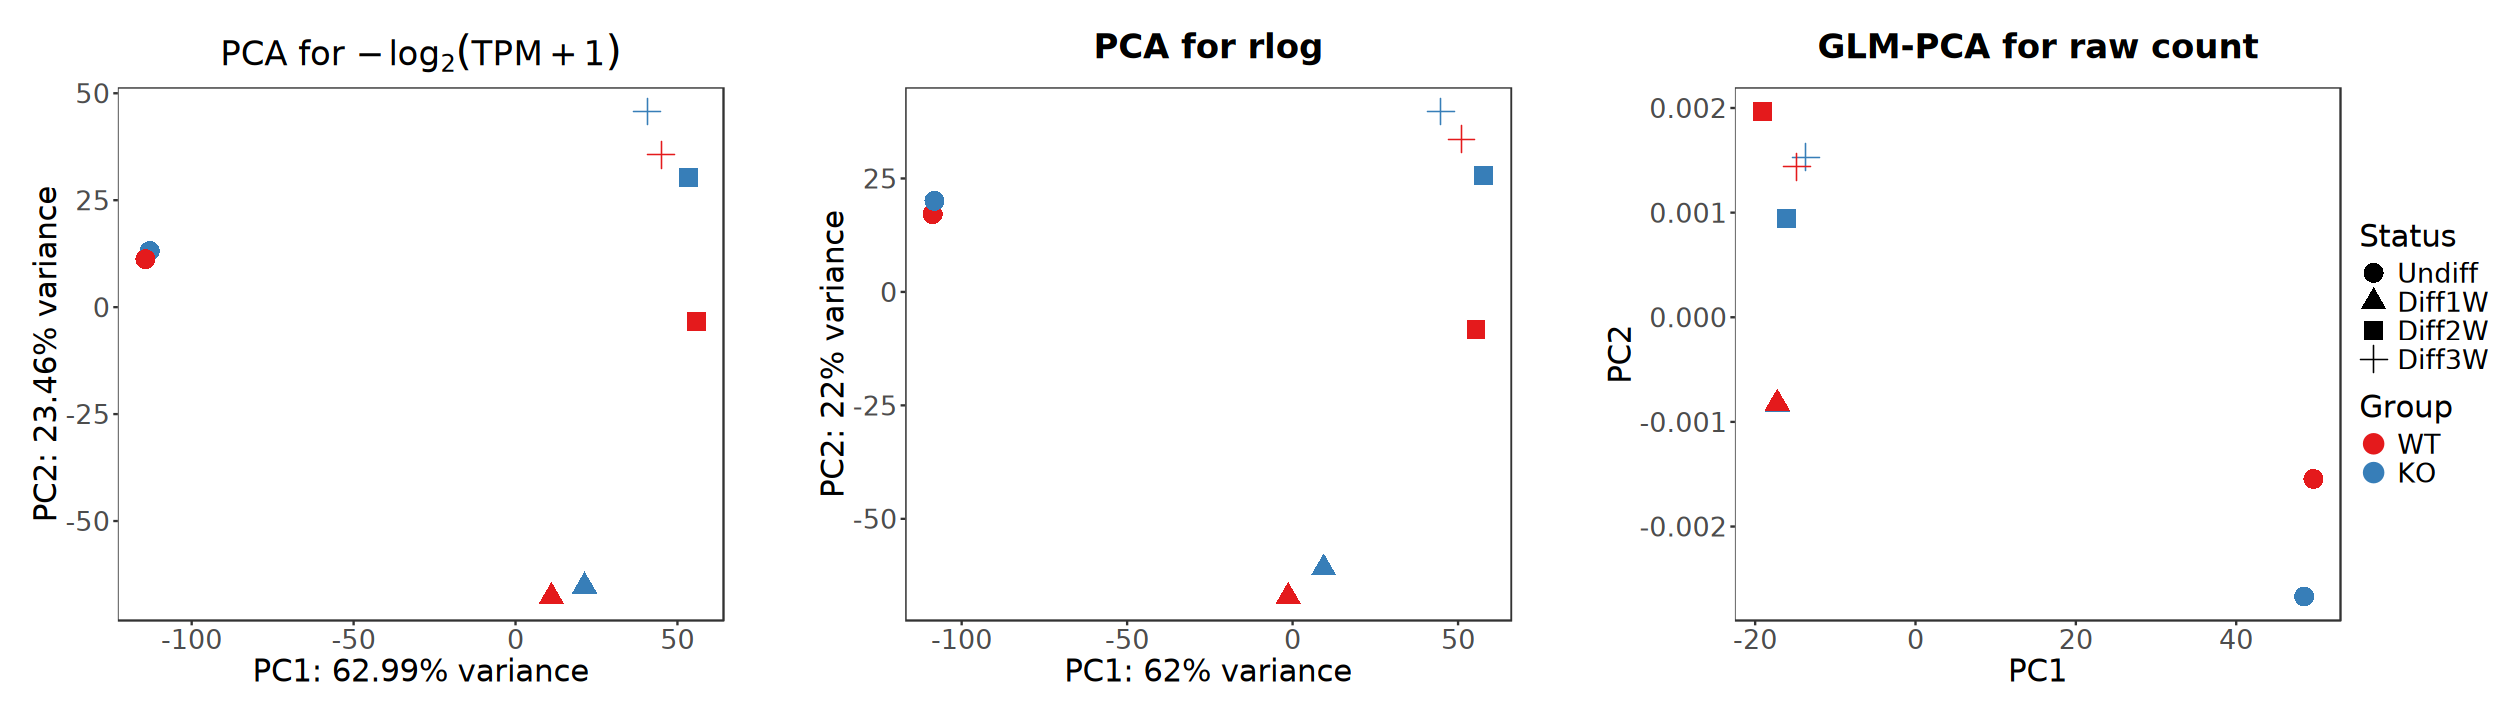

In [54]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [55]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

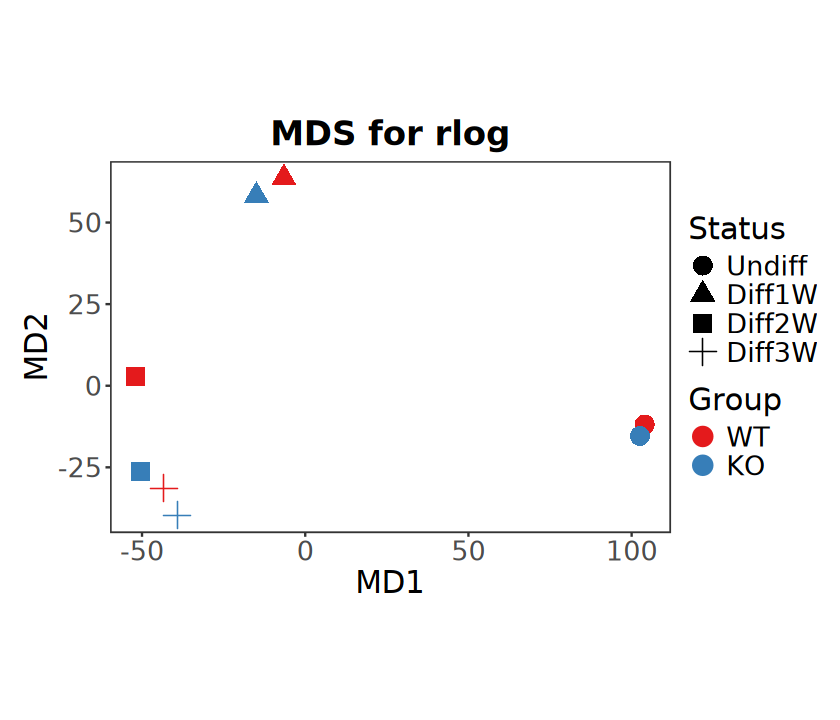

In [56]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Status), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [57]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

Warning message in vegan::vegdist(t(norm_vs[top_var_idx, ]), method = "bray"):
"results may be meaningless because data have negative entries
                 in method "bray""


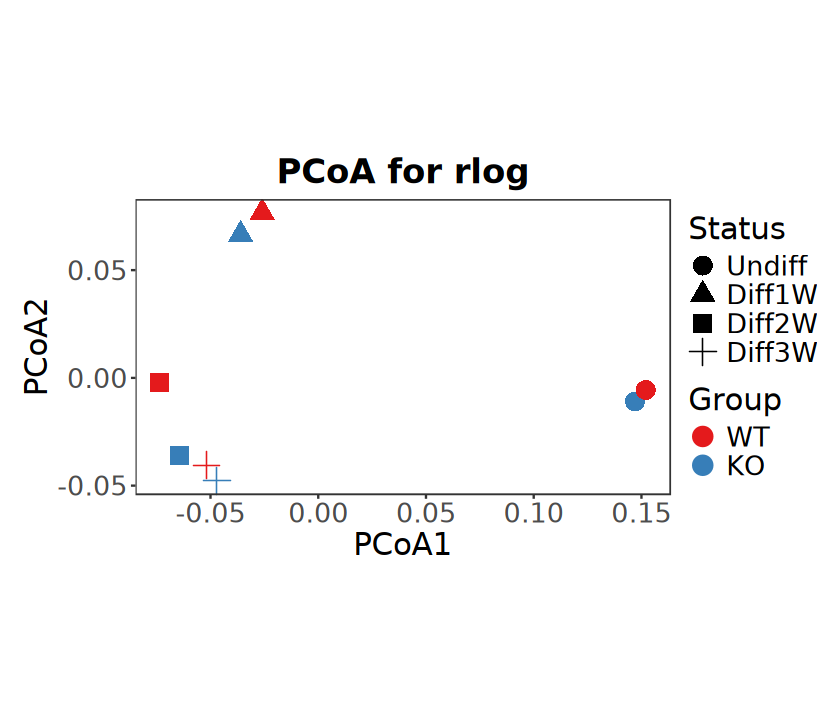

In [58]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Status), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [59]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Status, Group)

In [60]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Status)),
    levels(eSet$Status))

anno_colors <- list(
    Group = group_colors,
    Status = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [61]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

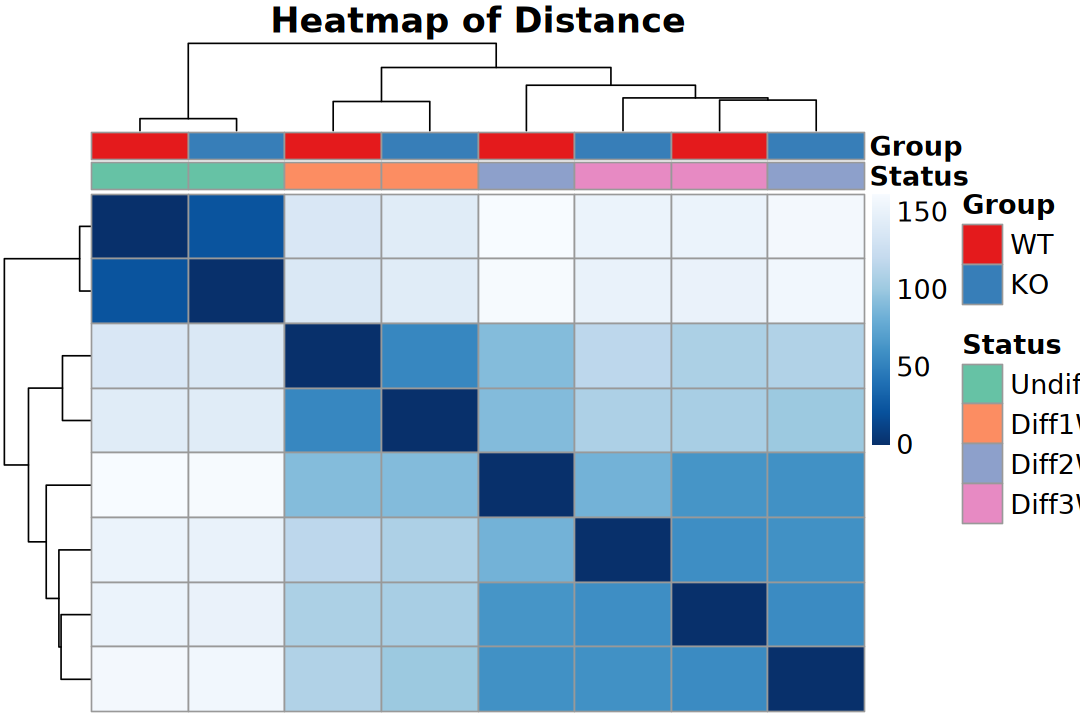

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [63]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

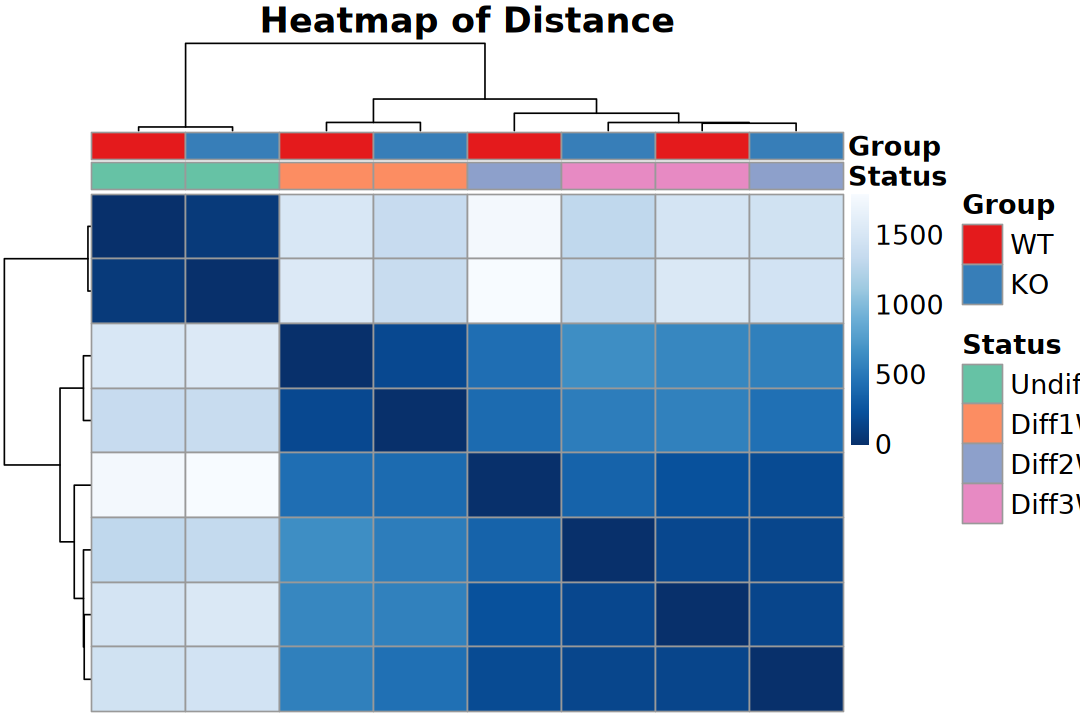

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

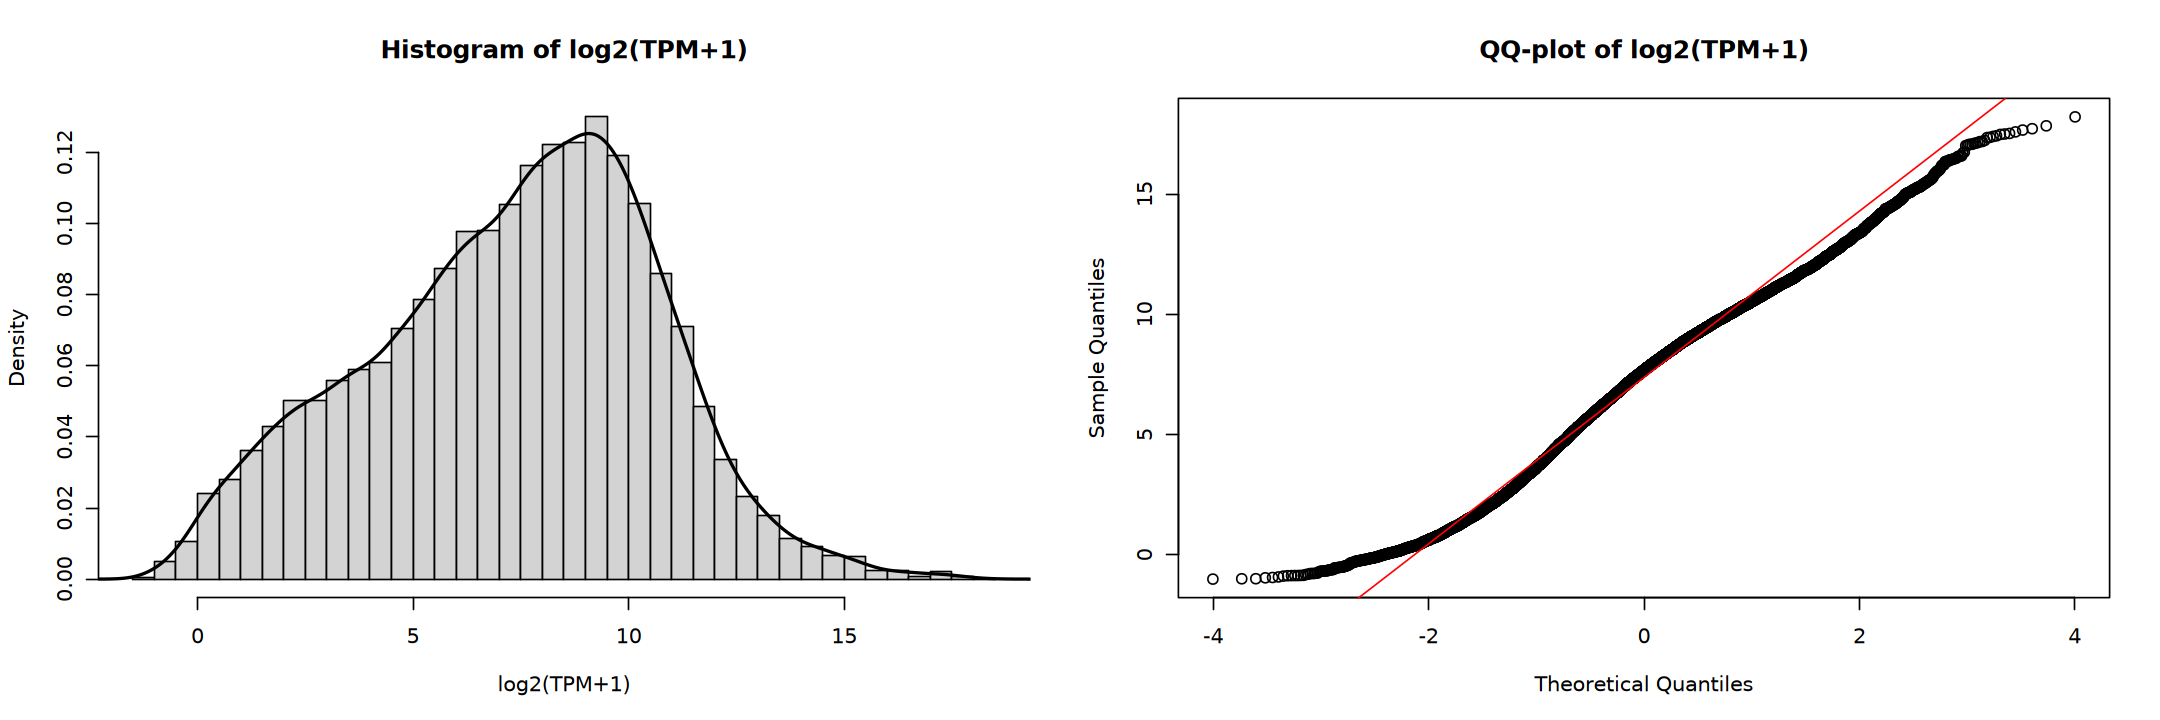

In [65]:
options(repr.plot.width = 18, repr.plot.height = 6)

par(mfrow = c(1, 2))
hist(
    norm_vs[top_var_idx, ], breaks = 50, probability = TRUE, 
    main = "Histogram of log2(TPM+1)", xlab = "log2(TPM+1)")
lines(density(norm_vs[top_var_idx, ]), lwd = 2)

qqnorm(
    norm_vs[top_var_idx, ], 
    main = "QQ-plot of log2(TPM+1)")
qqline(
    norm_vs[top_var_idx, ], col = "red")

par(mfrow = c(1, 1))

In [66]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

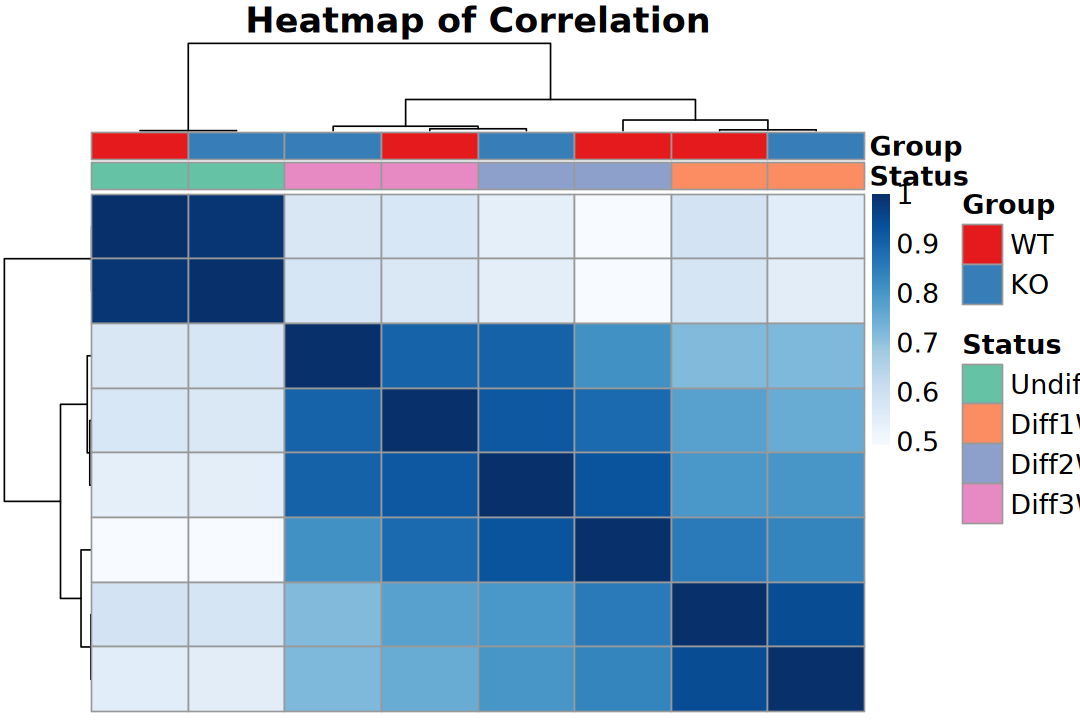

In [67]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

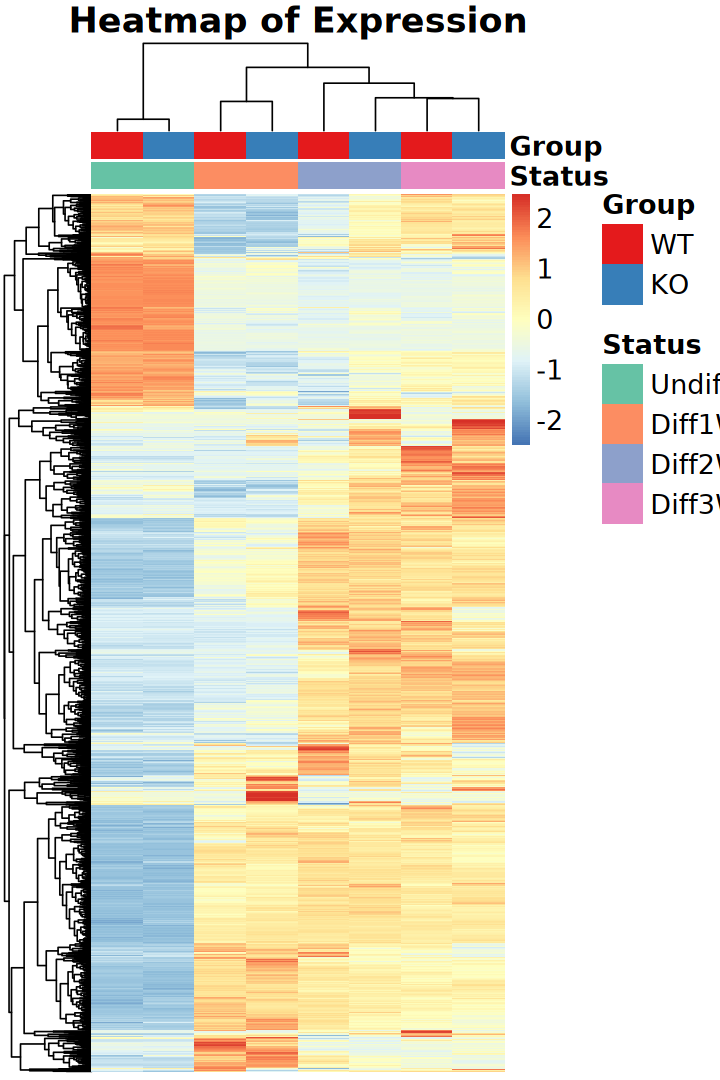

In [68]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [69]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [70]:
design(dds) <- ~ Status + Group
design(dds)

~Status + Group

In [71]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [72]:
resultsNames(dds)

[1] "Intercept"               "Status_Diff1W_vs_Undiff"
[3] "Status_Diff2W_vs_Undiff" "Status_Diff3W_vs_Undiff"
[5] "Group_KO_vs_WT"

### a). Standard

In [73]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Group_KO_vs_WT", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Group", "KO", "WT"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 25971 with nonzero total read count
adjusted p-value < 0.05
LFC > 0.26 (up)    : 181, 0.7%
LFC < -0.26 (down) : 93, 0.36%
outliers [1]       : 0, 0%
low counts [2]     : 4532, 17%
(mean count < 5)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [74]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
  181    93 25697 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,59.2595632,-0.4980817,0.3639243,-1.3686411,0.2774277,0.9999913,NS,Xkr4,protein_coding,6094
ENSMUSG00000025900.12,39.8528953,0.6901248,0.5256011,1.3130200,0.2431109,0.9999913,NS,Rp1,protein_coding,12311
ENSMUSG00000102948.1,0.6599798,0.6309877,3.4530989,0.1827309,0.8554246,NA,NS,Gm6101,processed_pseudogene,1867
ENSMUSG00000025902.13,473.5110213,0.1647738,0.3615321,0.4557652,0.7254493,0.9999913,NS,Sox17,protein_coding,4772
ENSMUSG00000102269.1,19.8352106,-0.2781848,0.6478066,-0.4294256,0.6923990,0.9999913,NS,Gm7357,processed_pseudogene,2991
ENSMUSG00000102735.1,5.6932372,1.2776999,1.1663974,1.0954242,0.2854353,0.9999913,NS,Gm7369,processed_pseudogene,936


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [75]:
res_lfc <- lfcShrink(dds, coef = "Group_KO_vs_WT", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 25971 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 583, 2.2%
LFC < 0 (down)     : 671, 2.6%
outliers [1]       : 0, 0%
low counts [2]     : 8056, 31%
(mean count < 15)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [76]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
  399   505 25067 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,59.2595632,-0.0572097597,0.1355927,0.1711115,0.6136012,NS,Xkr4,protein_coding,6094
ENSMUSG00000025900.12,39.8528953,0.0379277662,0.1299385,0.1891762,0.6366130,NS,Rp1,protein_coding,12311
ENSMUSG00000102948.1,0.6599798,-0.0001913165,0.1250838,0.8550092,NA,NS,Gm6101,processed_pseudogene,1867
ENSMUSG00000025902.13,473.5110213,0.0167246902,0.1200980,0.6485588,0.9290434,NS,Sox17,protein_coding,4772
ENSMUSG00000102269.1,19.8352106,-0.0095112511,0.1234619,0.6676135,0.9360663,NS,Gm7357,processed_pseudogene,2991
ENSMUSG00000102735.1,5.6932372,0.0118475786,0.1253945,0.2733308,NA,NS,Gm7369,processed_pseudogene,936


### Evaluate DEGs

In [77]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [78]:
genes_up <- list(
    raw = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    raw = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [79]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

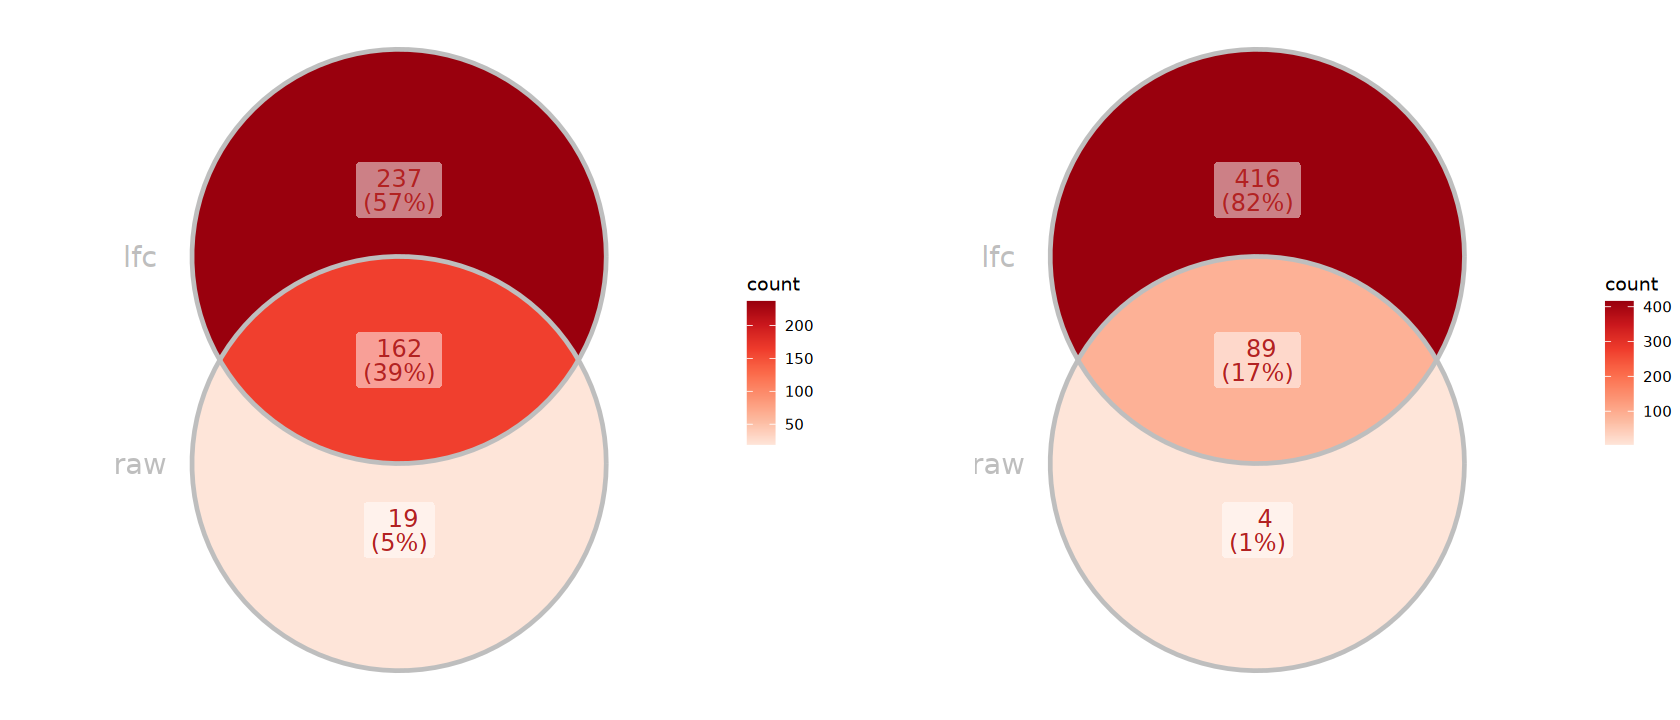

In [80]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

| Pipeline | Advantages | Application | Estimating dispersions | Fitting model | Testing methods | Notes |
| - | - | - | - | - | - | - |
| Classic pipeline (edgeR v1) | - | Single factor design | quantile-adjusted conditional maximum likelihood (qCML) method | Negative binomial model | Exact test (like Fisher’s exact test) | - |
| Negative binomial GLM framework (edgeR v2) | - | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | Negative binomial - Generalized linear model (NB GLM) | Likelihood ratio test (LRT) | - |
| Quasi-likelihood pipeline (edgeR v3) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | - |
| Quasi-likelihood pipeline (edgeR v4) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Estimates a constant NB dispersion based on the most highly expressed genes | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | Default and Recommended approach in edgeR |

### a). Classic pipeline

In [81]:
dgel_classic <- estimateDisp(dgel)
# # 1. Estimate common dispersion
# dgel <- estimateCommonDisp(dgel)
# # 2. Estimate tagwise dispersions
# dgel <- estimateTagwiseDisp(dgel)

Using classic mode.



In [82]:
# exact test
et <- exactTest(dgel_classic, pair = c("WT", "KO"))

In [83]:
edger_classic_result <- topTags(et, n = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_classic_result$result)
head(edger_classic_result)


   Up  Down    NS 
   16     0 20078 

,symbol,type,basepairs,logFC,logCPM,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000084803.8,5830444B04Rik,lncRNA,5410,5.379109,1.682053,8.667903e-07,0.01249414,Up
ENSMUSG00000079627.2,Rhox2h,protein_coding,787,5.781728,-1.832375,1.243570e-06,0.01249414,Up
ENSMUSG00000110537.1,Gm4316,lncRNA,3533,6.056128,1.494497,3.704070e-06,0.02480986,Up
ENSMUSG00000109588.1,Lnp1,protein_coding,671,7.211442,1.773369,1.524627e-05,0.04450201,Up
ENSMUSG00000095180.8,Rhox5,protein_coding,754,2.206282,6.345595,1.661510e-05,0.04450201,Up
ENSMUSG00000074489.9,Bglap3,protein_coding,2629,3.470727,1.065804,1.790125e-05,0.04450201,Up


### b). Negative binomial GLM framework

In [84]:
design <- model.matrix(~ group + Status, data = dgel$samples) # include intercept
design

,(Intercept),groupKO,StatusDiff1W,StatusDiff2W,StatusDiff3W
WT_Undiff,1,0,0,0,0
WT_Diff1W,1,0,1,0,0
WT_Diff2W,1,0,0,1,0
WT_Diff3W,1,0,0,0,1
KO_Undiff,1,1,0,0,0
KO_Diff1W,1,1,1,0,0
KO_Diff2W,1,1,0,1,0
KO_Diff3W,1,1,0,0,1


In [85]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [86]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

In [87]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
  403   387 19304 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000109588.1,Lnp1,protein_coding,671,7.214340,1.65925556,138.84648,4.758483e-32,9.561696e-28,Up
ENSMUSG00000024653.2,Scgb1a1,protein_coding,476,10.468716,3.14290805,124.81407,5.589401e-29,5.615671e-25,Up
ENSMUSG00000038791.14,Scgb3a2,protein_coding,880,4.851360,4.35133699,79.76071,4.226132e-19,2.830663e-15,Up
ENSMUSG00000079298.9,Klrb1b,protein_coding,2228,7.776097,0.28859360,77.88264,1.093480e-18,5.493095e-15,Up
ENSMUSG00000052014.6,A330070K13Rik,protein_coding,706,7.017647,-0.01599747,77.15197,1.582963e-18,6.361613e-15,Up
ENSMUSG00000114982.1,Vmn1r14,protein_coding,7542,4.225941,0.62349176,74.79707,5.216709e-18,1.747076e-14,Up


### c). Quasi-likelihood pipeline (edgeR v3)

In [88]:
design <- model.matrix(~ group + Status, data = dgel$samples) # include intercept

In [89]:
dgel_nbglm <- estimateDisp(dgel, design)

In [90]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

In [91]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
  151   122 19821 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000109588.1,Lnp1,protein_coding,671,7.125719,1.65925556,296.8238,2.804126e-08,0.0005634611,Up
ENSMUSG00000100816.1,Gm28321,lncRNA,2327,4.078195,-0.64520272,106.7300,1.987492e-06,0.0106814470,Up
ENSMUSG00000035395.11,Pet2,protein_coding,4183,6.311495,2.31768481,172.0354,2.313424e-06,0.0106814470,Up
ENSMUSG00000052014.6,A330070K13Rik,protein_coding,706,7.050984,-0.01599747,178.5608,2.866501e-06,0.0106814470,Up
ENSMUSG00000114982.1,Vmn1r14,protein_coding,7542,4.147785,0.62349176,159.3132,3.119209e-06,0.0106814470,Up
ENSMUSG00000084980.1,Slc36a1os,lncRNA,1938,6.505883,0.36912718,101.5863,3.189444e-06,0.0106814470,Up


### d). Quasi-likelihood pipeline (edgeR v4)

In [92]:
design <- model.matrix(~ group + Status, data = dgel$samples) # include intercept

In [93]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [94]:
edger_glm_qlf_v4_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_v4_result$result)
head(edger_glm_qlf_v4_result)


   Up  Down    NS 
  147   119 19828 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000109588.1,Lnp1,protein_coding,671,7.125906,1.6049036,297.2549,2.821825e-08,0.0005670174,Up
ENSMUSG00000100816.1,Gm28321,lncRNA,2327,4.078063,-0.7542538,107.9199,1.958542e-06,0.0104203971,Up
ENSMUSG00000035395.11,Pet2,protein_coding,4183,6.311842,2.2832324,171.0708,2.410163e-06,0.0104203971,Up
ENSMUSG00000052014.6,A330070K13Rik,protein_coding,706,7.050936,-0.1577198,184.2989,2.471993e-06,0.0104203971,Up
ENSMUSG00000114982.1,Vmn1r14,protein_coding,7542,4.147868,0.5288806,161.8527,3.040836e-06,0.0104203971,Up
ENSMUSG00000084980.1,Slc36a1os,lncRNA,1938,6.505495,0.2495377,102.3464,3.111495e-06,0.0104203971,Up


### Evaluate DEGs

In [95]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [96]:
genes_up <- list(
    classic = edger_classic_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    classic = edger_classic_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [97]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

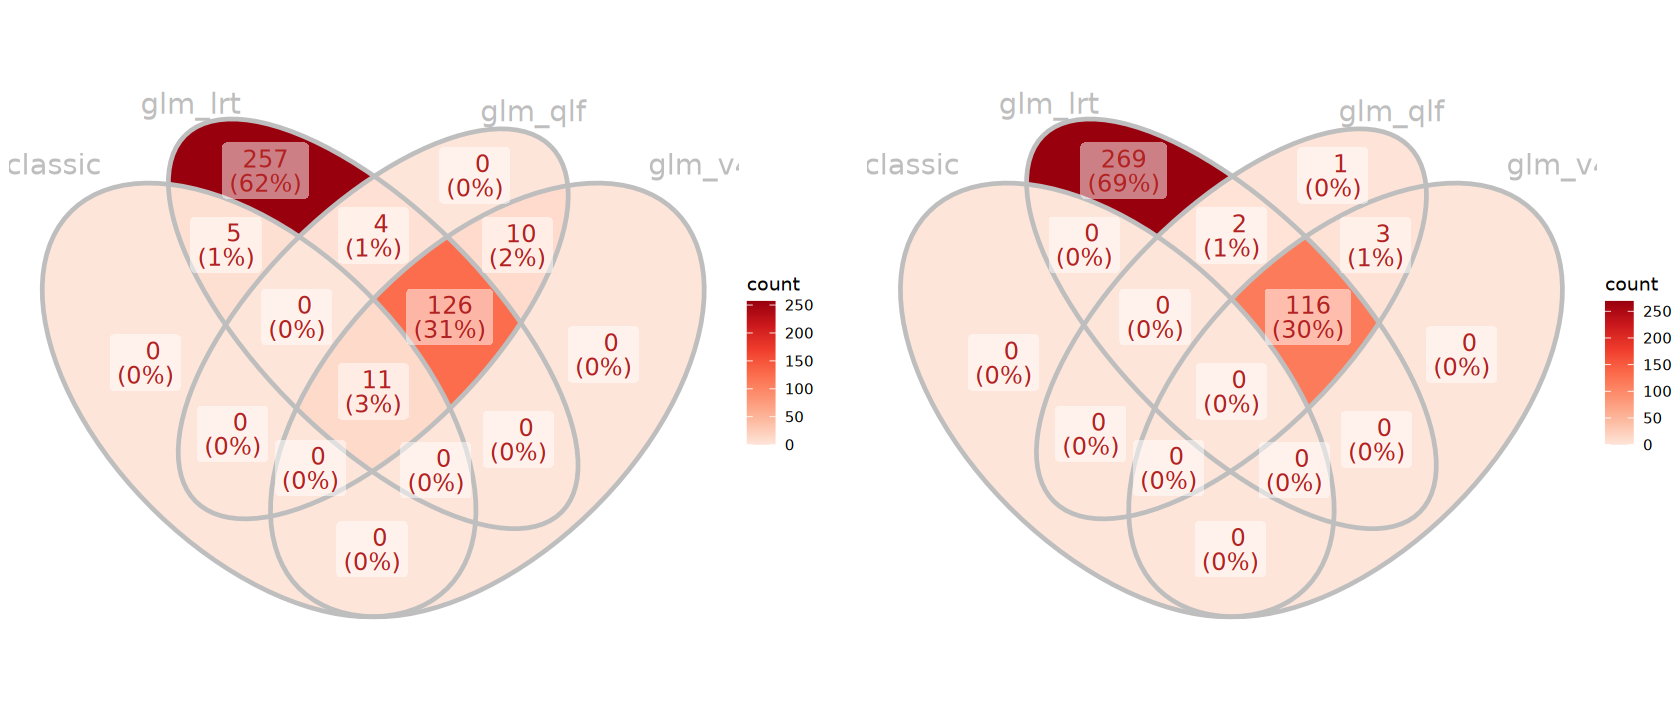

In [98]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

### a). limma-trend

> If the sequencing depth is fairly consistent across the RNA samples, then the simplest and most reliable method for differential expression is to use limma-trend. This method usually works well if the ratio of the largest library size to the smallest is no more than about 3-fold. Few literature uses.

In [99]:
design <- model.matrix(~ group + Status, data = dgel$samples)
design

,(Intercept),groupKO,StatusDiff1W,StatusDiff2W,StatusDiff3W
WT_Undiff,1,0,0,0,0
WT_Diff1W,1,0,1,0,0
WT_Diff2W,1,0,0,1,0
WT_Diff3W,1,0,0,0,1
KO_Undiff,1,1,0,0,0
KO_Diff1W,1,1,1,0,0
KO_Diff2W,1,1,0,1,0
KO_Diff3W,1,1,0,0,1


In [100]:
logCPM <- cpm(dgel, normalized.lib.sizes = TRUE, log = TRUE)

In [101]:
# Linear Model for Series of Arrays
fit <- lmFit(logCPM, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit, trend = TRUE)

In [ ]:
limma_trend_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_trend_result <- topTable(efit, coef = "groupRA", number = Inf) |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        dgel$genes |> rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(limma_trend_result$result)
head(limma_trend_result)


   Up  Down    NS 
    0     0 20094 

,logFC,AveExpr,t,pvalue,padj,B,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000029231.15,1.0045277,6.2485615,10.630407,1.556785e-05,0.05417746,3.398081,NS,Pdgfra,protein_coding,10024
ENSMUSG00000001472.17,-0.7549876,8.0993028,-10.109932,2.162118e-05,0.05417746,3.147411,NS,Tcf25,protein_coding,5390
ENSMUSG00000060586.11,2.8172309,1.8472179,9.351320,3.588518e-05,0.05417746,2.746274,NS,H2-Eb1,protein_coding,1944
ENSMUSG00000114982.1,4.0023160,-0.6229698,9.314332,3.681617e-05,0.05417746,2.725546,NS,Vmn1r14,protein_coding,7542
ENSMUSG00000036550.16,-0.7245517,9.1378364,-9.228819,3.907532e-05,0.05417746,2.677186,NS,Cnot1,protein_coding,17169
ENSMUSG00000031529.5,-0.8019595,8.3926833,-9.111583,4.243278e-05,0.05417746,2.609879,NS,Tnks,protein_coding,14888


### b). limma-voom

> When library sizes vary significantly between samples, the voom approach is technically more powerful than limma-trend.

In [103]:
design <- model.matrix(~ group + Status, data = dgel$samples)

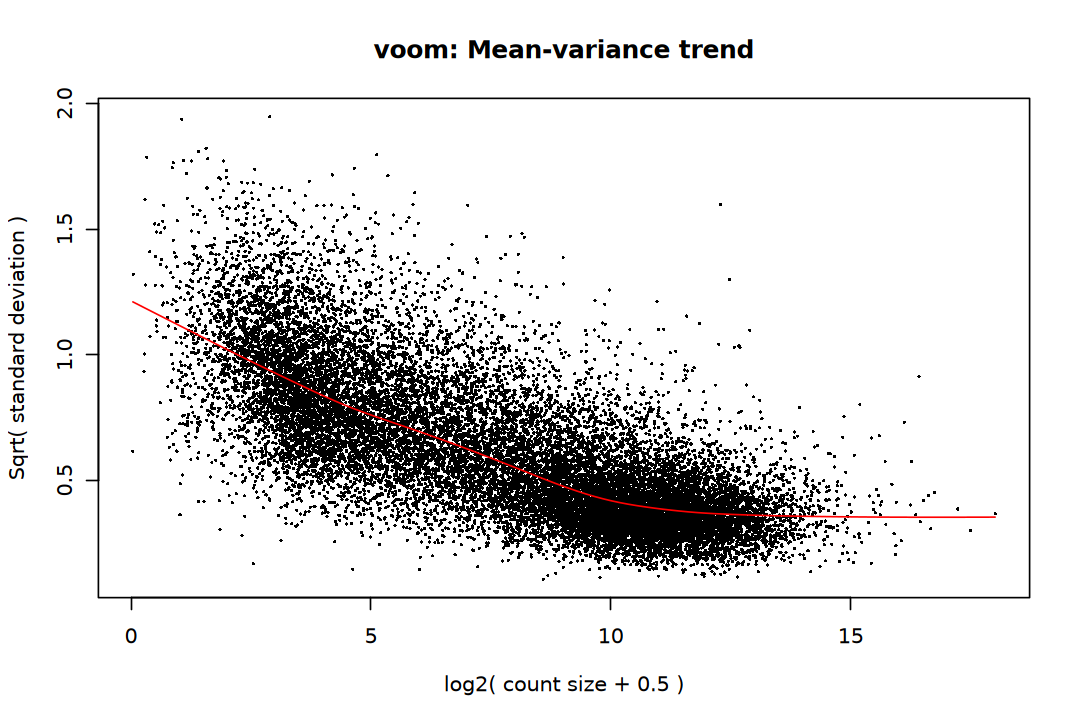

In [104]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [105]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [106]:
limma_voom_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voom_result <- topTable(efit, coef = "groupKO", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
   77    85 19932 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000020077.14,Srgn,protein_coding,2196,1.7466741,4.3157563,10.849742,1.422140e-05,0.0442233,3.891080,Up
ENSMUSG00000029231.15,Pdgfra,protein_coding,10024,1.0024953,6.2465224,10.458320,1.807380e-05,0.0442233,3.569097,Up
ENSMUSG00000001472.17,Tcf25,protein_coding,5390,-0.7556425,8.0992109,-10.263100,2.043078e-05,0.0442233,3.384936,Down
ENSMUSG00000038791.14,Scgb3a2,protein_coding,880,5.1288988,-1.8329783,11.479707,9.824478e-06,0.0442233,3.350955,Up
ENSMUSG00000079584.2,Gm364,protein_coding,2156,2.8738043,0.9551551,9.873955,2.625120e-05,0.0442233,3.087949,Up
ENSMUSG00000028128.13,F3,protein_coding,2527,1.0907074,5.3539096,9.661774,3.020765e-05,0.0442233,3.072369,Up


### c). voomLmFit

> In recent versions of limma and edgeR, we now recommend voomLmFit as the preferred interface for RNA-seq analyses, replacing voom, lmFit, and voomWithQualityWeights. voomLmFit ensures unbiased estimation of the residual variances, even for genes that have no counts at all in some experimental conditions.
> - voomLmFit = voom transform + lmFit with weights

In [107]:
design <- model.matrix(~ group + Status, data = dgel$samples)

In [108]:
# sample.weights = TRUE: estimating the empirical sample quality weights
fit <- voomLmFit(dgel, design = design, sample.weights = TRUE)
efit <- eBayes(fit)

First sample weights (min/max) 0.5713361/1.5499794

Final sample weights (min/max) 0.5508067/1.5673739



In [109]:
limma_voomLmFit_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voomLmFit_result <- topTable(efit, coef = "groupKO", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voomLmFit_result$result)
head(limma_voomLmFit_result)


   Up  Down    NS 
  113   121 19860 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000031125.2,3830403N18Rik,protein_coding,1022,3.628840,1.384030,12.25879,7.670732e-06,0.03150923,4.026149,Up
ENSMUSG00000061527.7,Krt5,protein_coding,2197,2.027322,2.477949,11.05408,1.492026e-05,0.03150923,3.861011,Up
ENSMUSG00000021795.10,Sftpd,protein_coding,2417,3.361500,-0.600833,11.37231,1.243807e-05,0.03150923,3.852034,Up
ENSMUSG00000021765.9,Fst,protein_coding,4589,1.206612,3.769096,10.73982,1.794201e-05,0.03150923,3.672399,Up
ENSMUSG00000038791.14,Scgb3a2,protein_coding,880,5.267251,-1.832978,14.70054,9.322559e-06,0.03150923,3.617522,Up
ENSMUSG00000020077.14,Srgn,protein_coding,2196,1.754497,4.315756,10.64650,1.896985e-05,0.03150923,3.604313,Up


### Evaluate DEGs

In [110]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    trend = limma_trend_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    trend = limma_trend_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [112]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

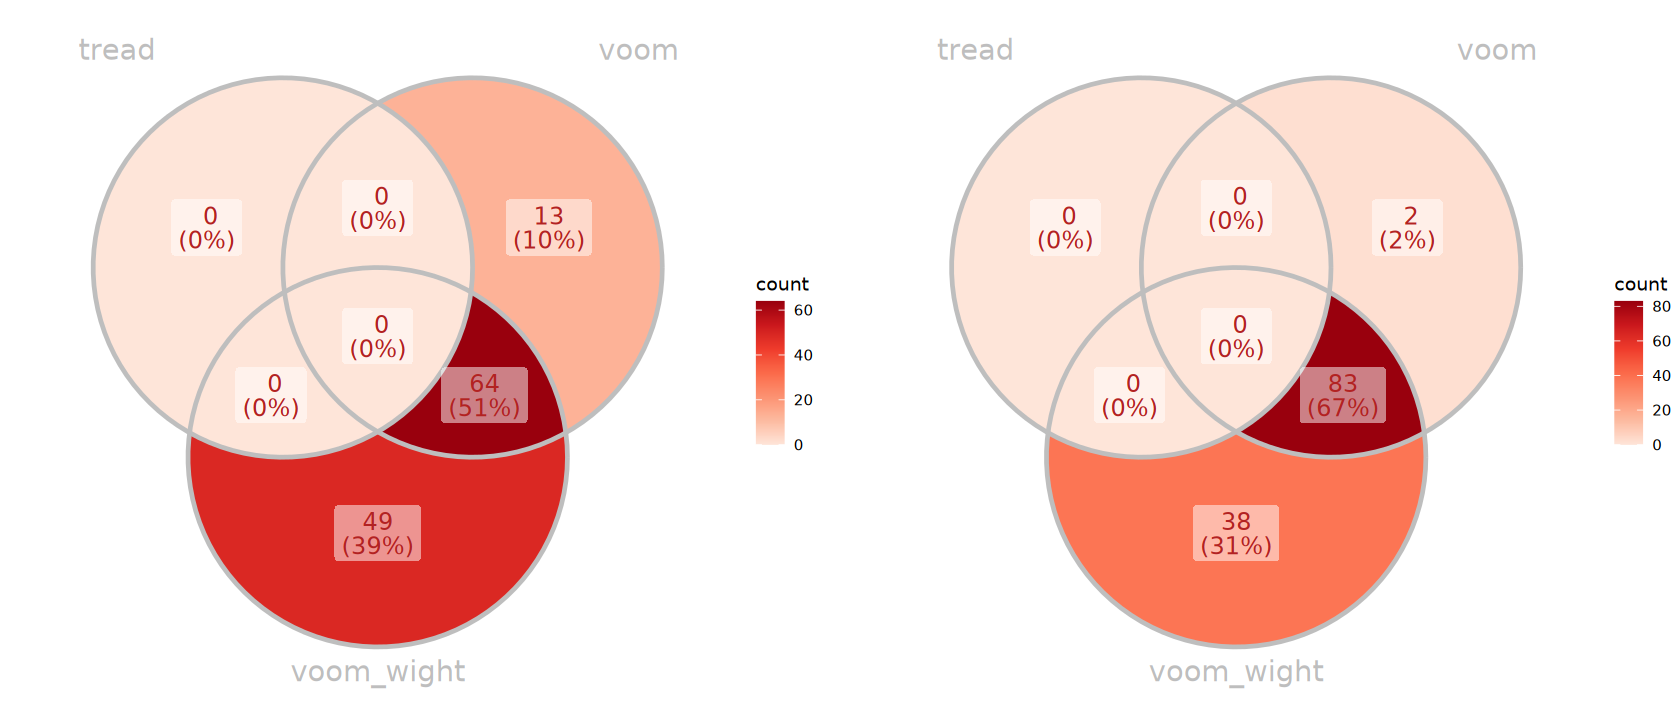

In [113]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Evaluation

In [114]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 10,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [115]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_qlf_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### P-value Histogram

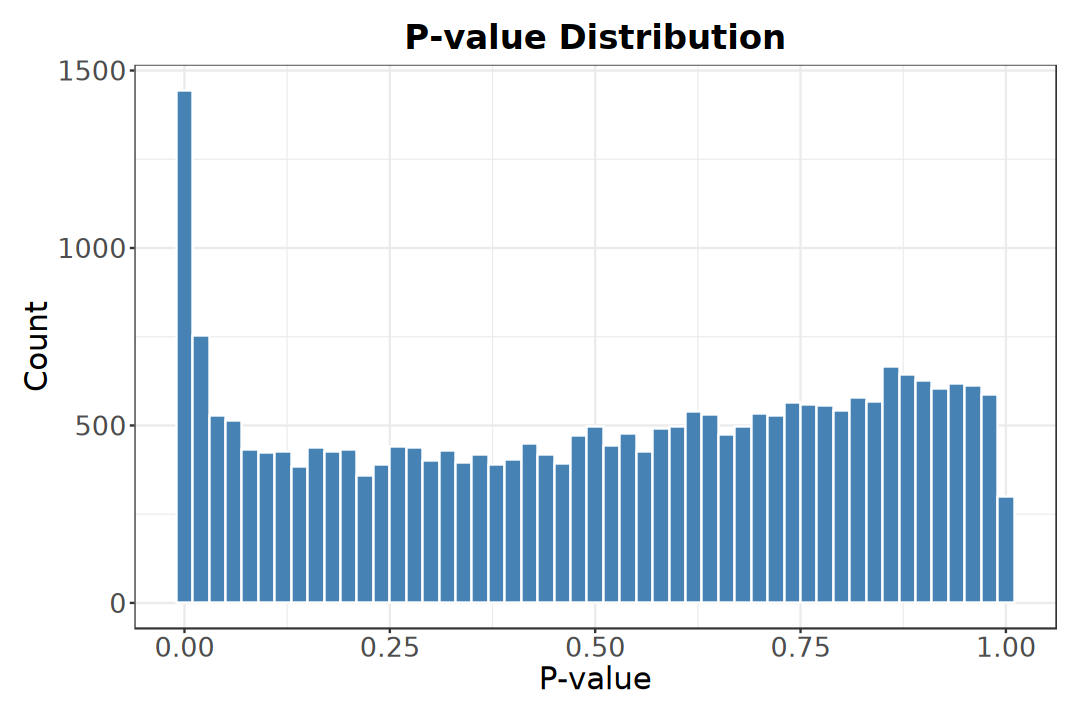

In [116]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [117]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [118]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

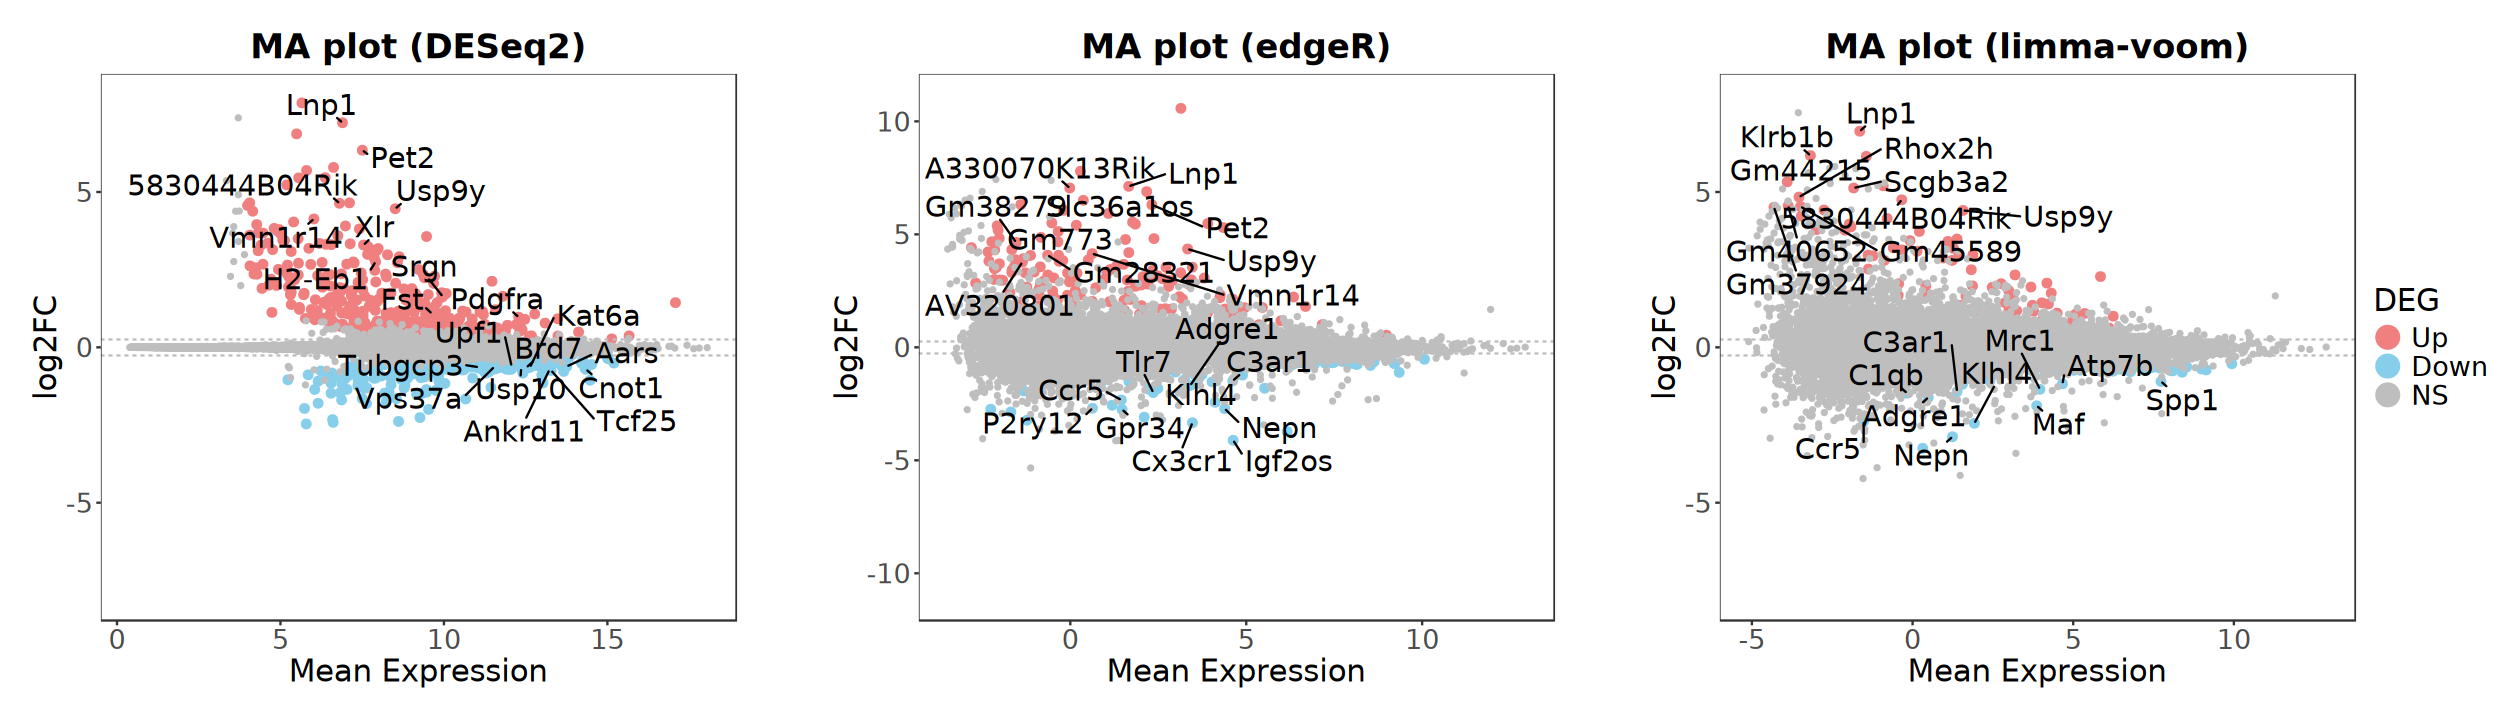

In [119]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [120]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [121]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

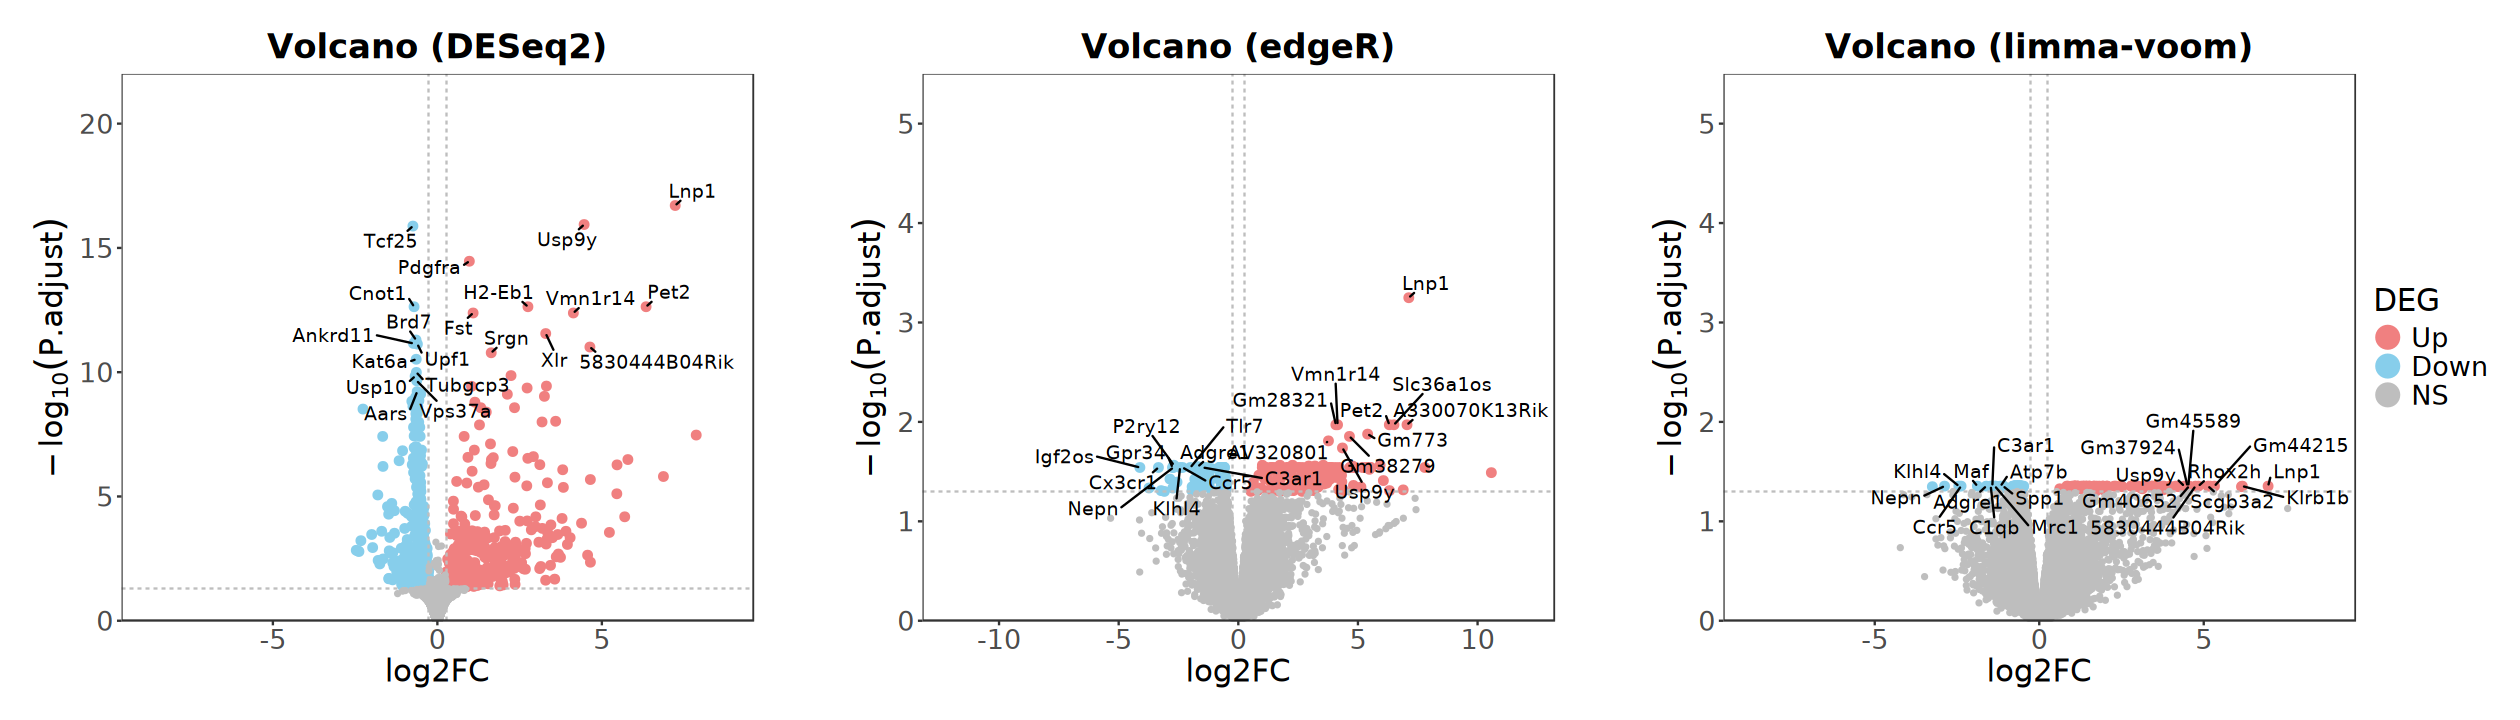

In [122]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [123]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [124]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [125]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

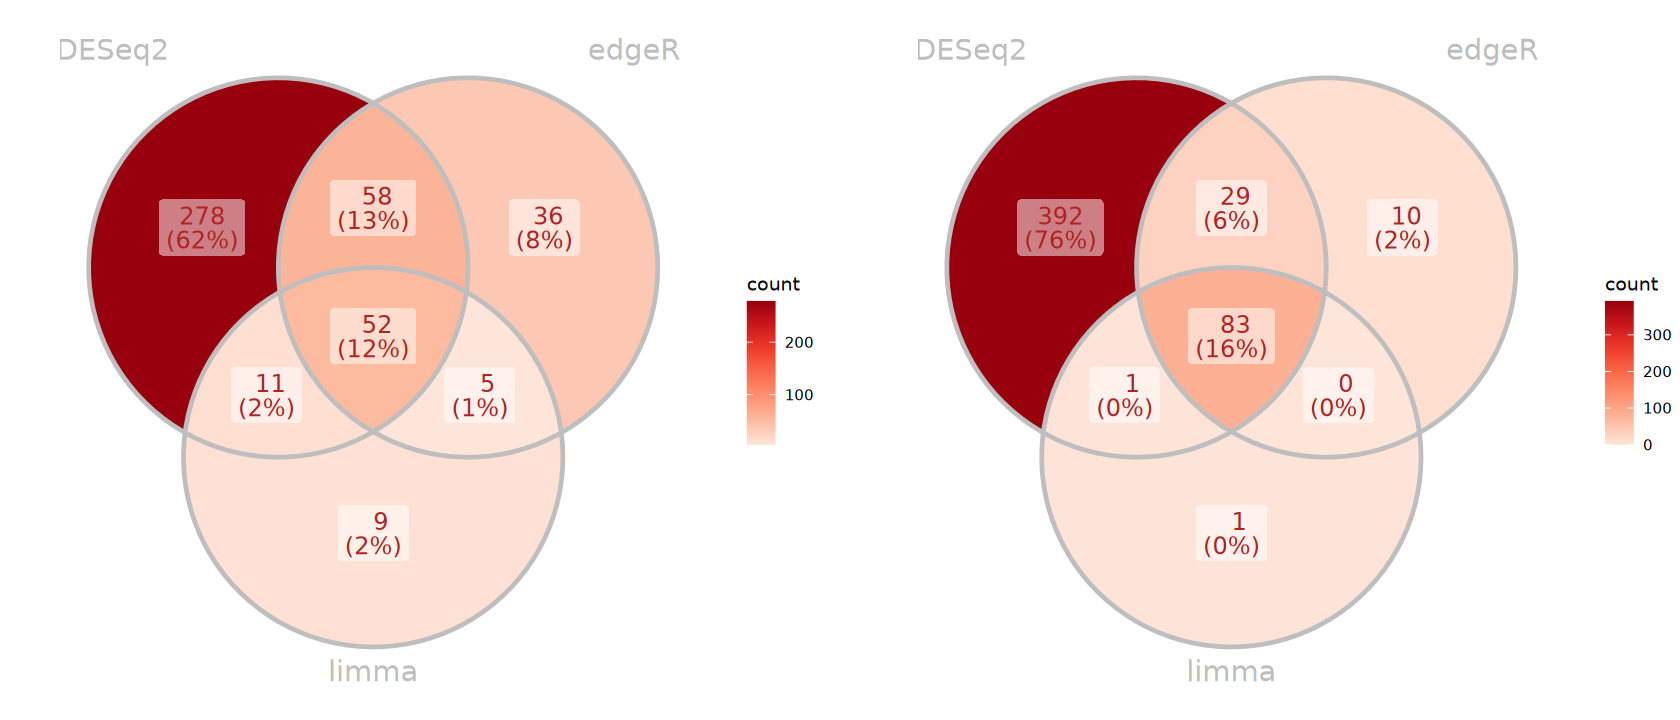

In [126]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [127]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>."
Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>."


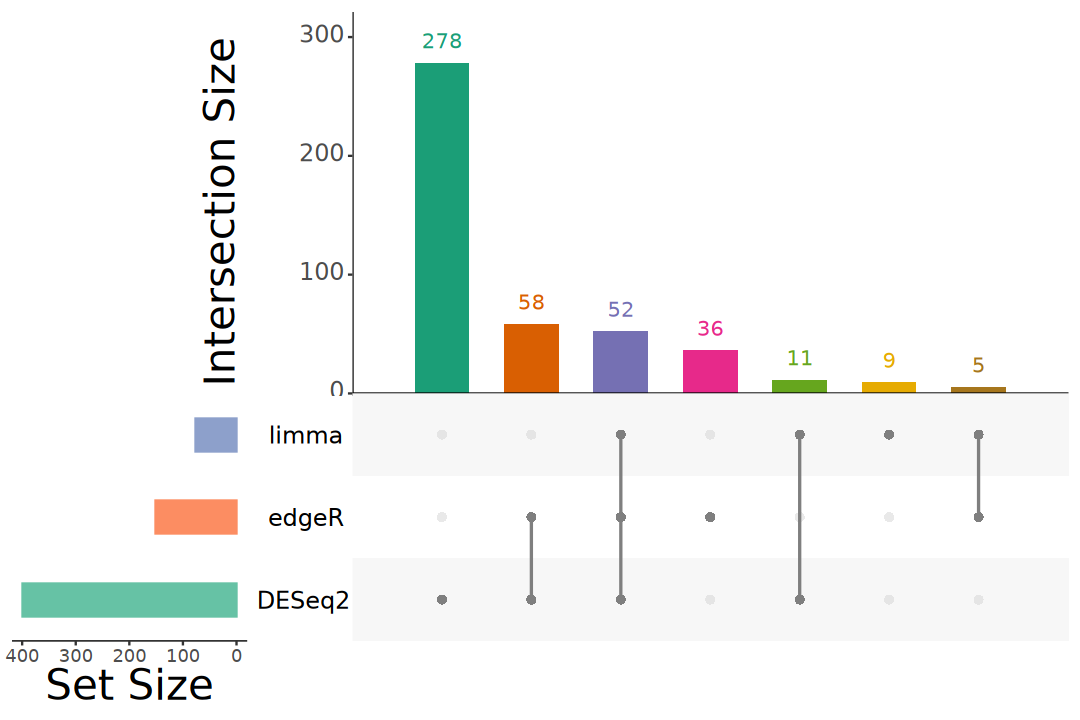

In [128]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

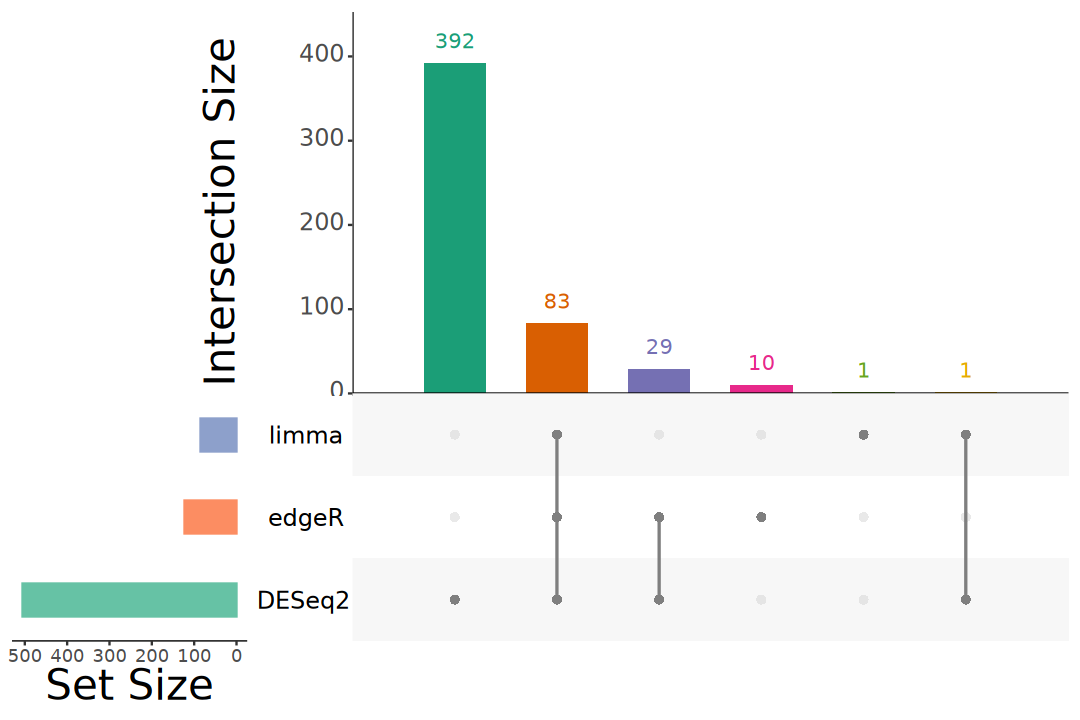

In [129]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 6, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

## DEGs Visualization

In [130]:
res_lfc <- lfcShrink(dds, coef = "Group_KO_vs_WT", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 25971 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 583, 2.2%
LFC < 0 (down)     : 671, 2.6%
outliers [1]       : 0, 0%
low counts [2]     : 8056, 31%
(mean count < 15)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [131]:
degs_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)


   Up  Down    NS 
  399   505 25067 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
ENSMUSG00000109588.1,118.1617,7.2294562,0.78186925,1.097440e-21,1.966064e-17,Up,Lnp1,protein_coding,671,Lnp1
ENSMUSG00000069044.6,363.7354,4.4607766,0.52644073,1.276331e-20,1.143273e-16,Up,Usp9y,protein_coding,8094,Usp9y
ENSMUSG00000001472.17,9935.0210,-0.7431648,0.08318298,2.211016e-20,1.320345e-16,Down,Tcf25,protein_coding,5390,Tcf25
ENSMUSG00000029231.15,4994.7915,0.9718045,0.11415594,7.663283e-19,3.432193e-15,Up,Pdgfra,protein_coding,10024,Pdgfra
ENSMUSG00000035395.11,180.5542,6.3443547,0.88535653,8.246813e-17,2.321801e-13,Up,Pet2,protein_coding,4183,Pet2
ENSMUSG00000060586.11,239.2638,2.7527997,0.35233554,7.704534e-17,2.321801e-13,Up,H2-Eb1,protein_coding,1944,H2-Eb1


In [132]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA plot

> - Mean-Difference plot
> - Bland-Altman plot

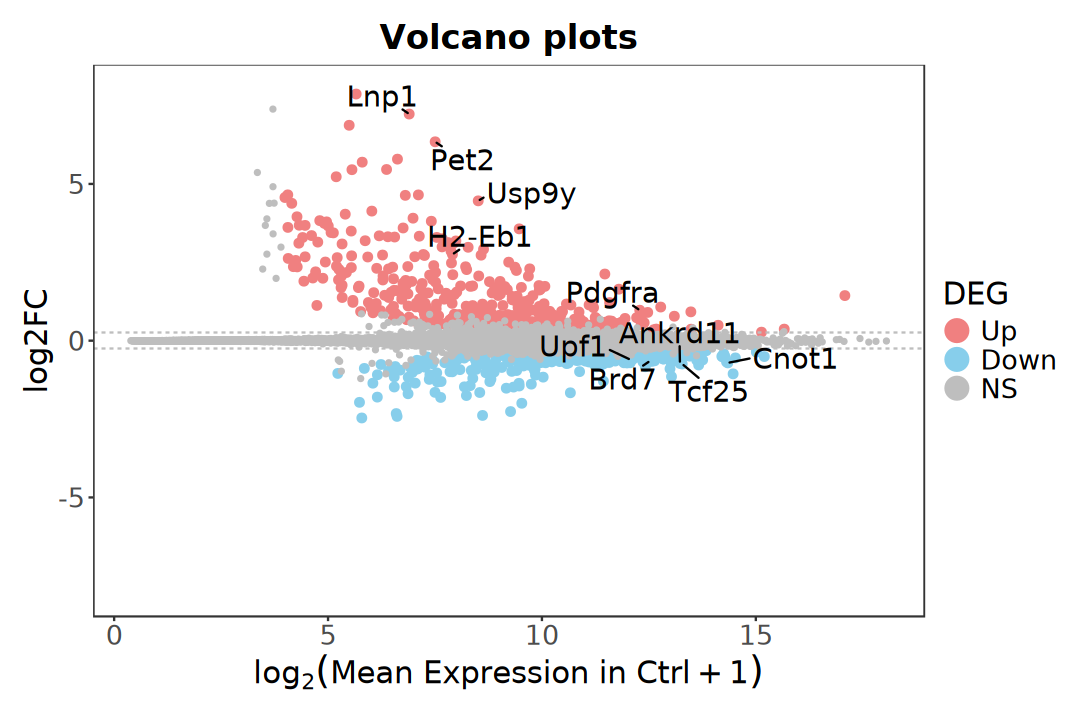

In [133]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [134]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [135]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [136]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [137]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

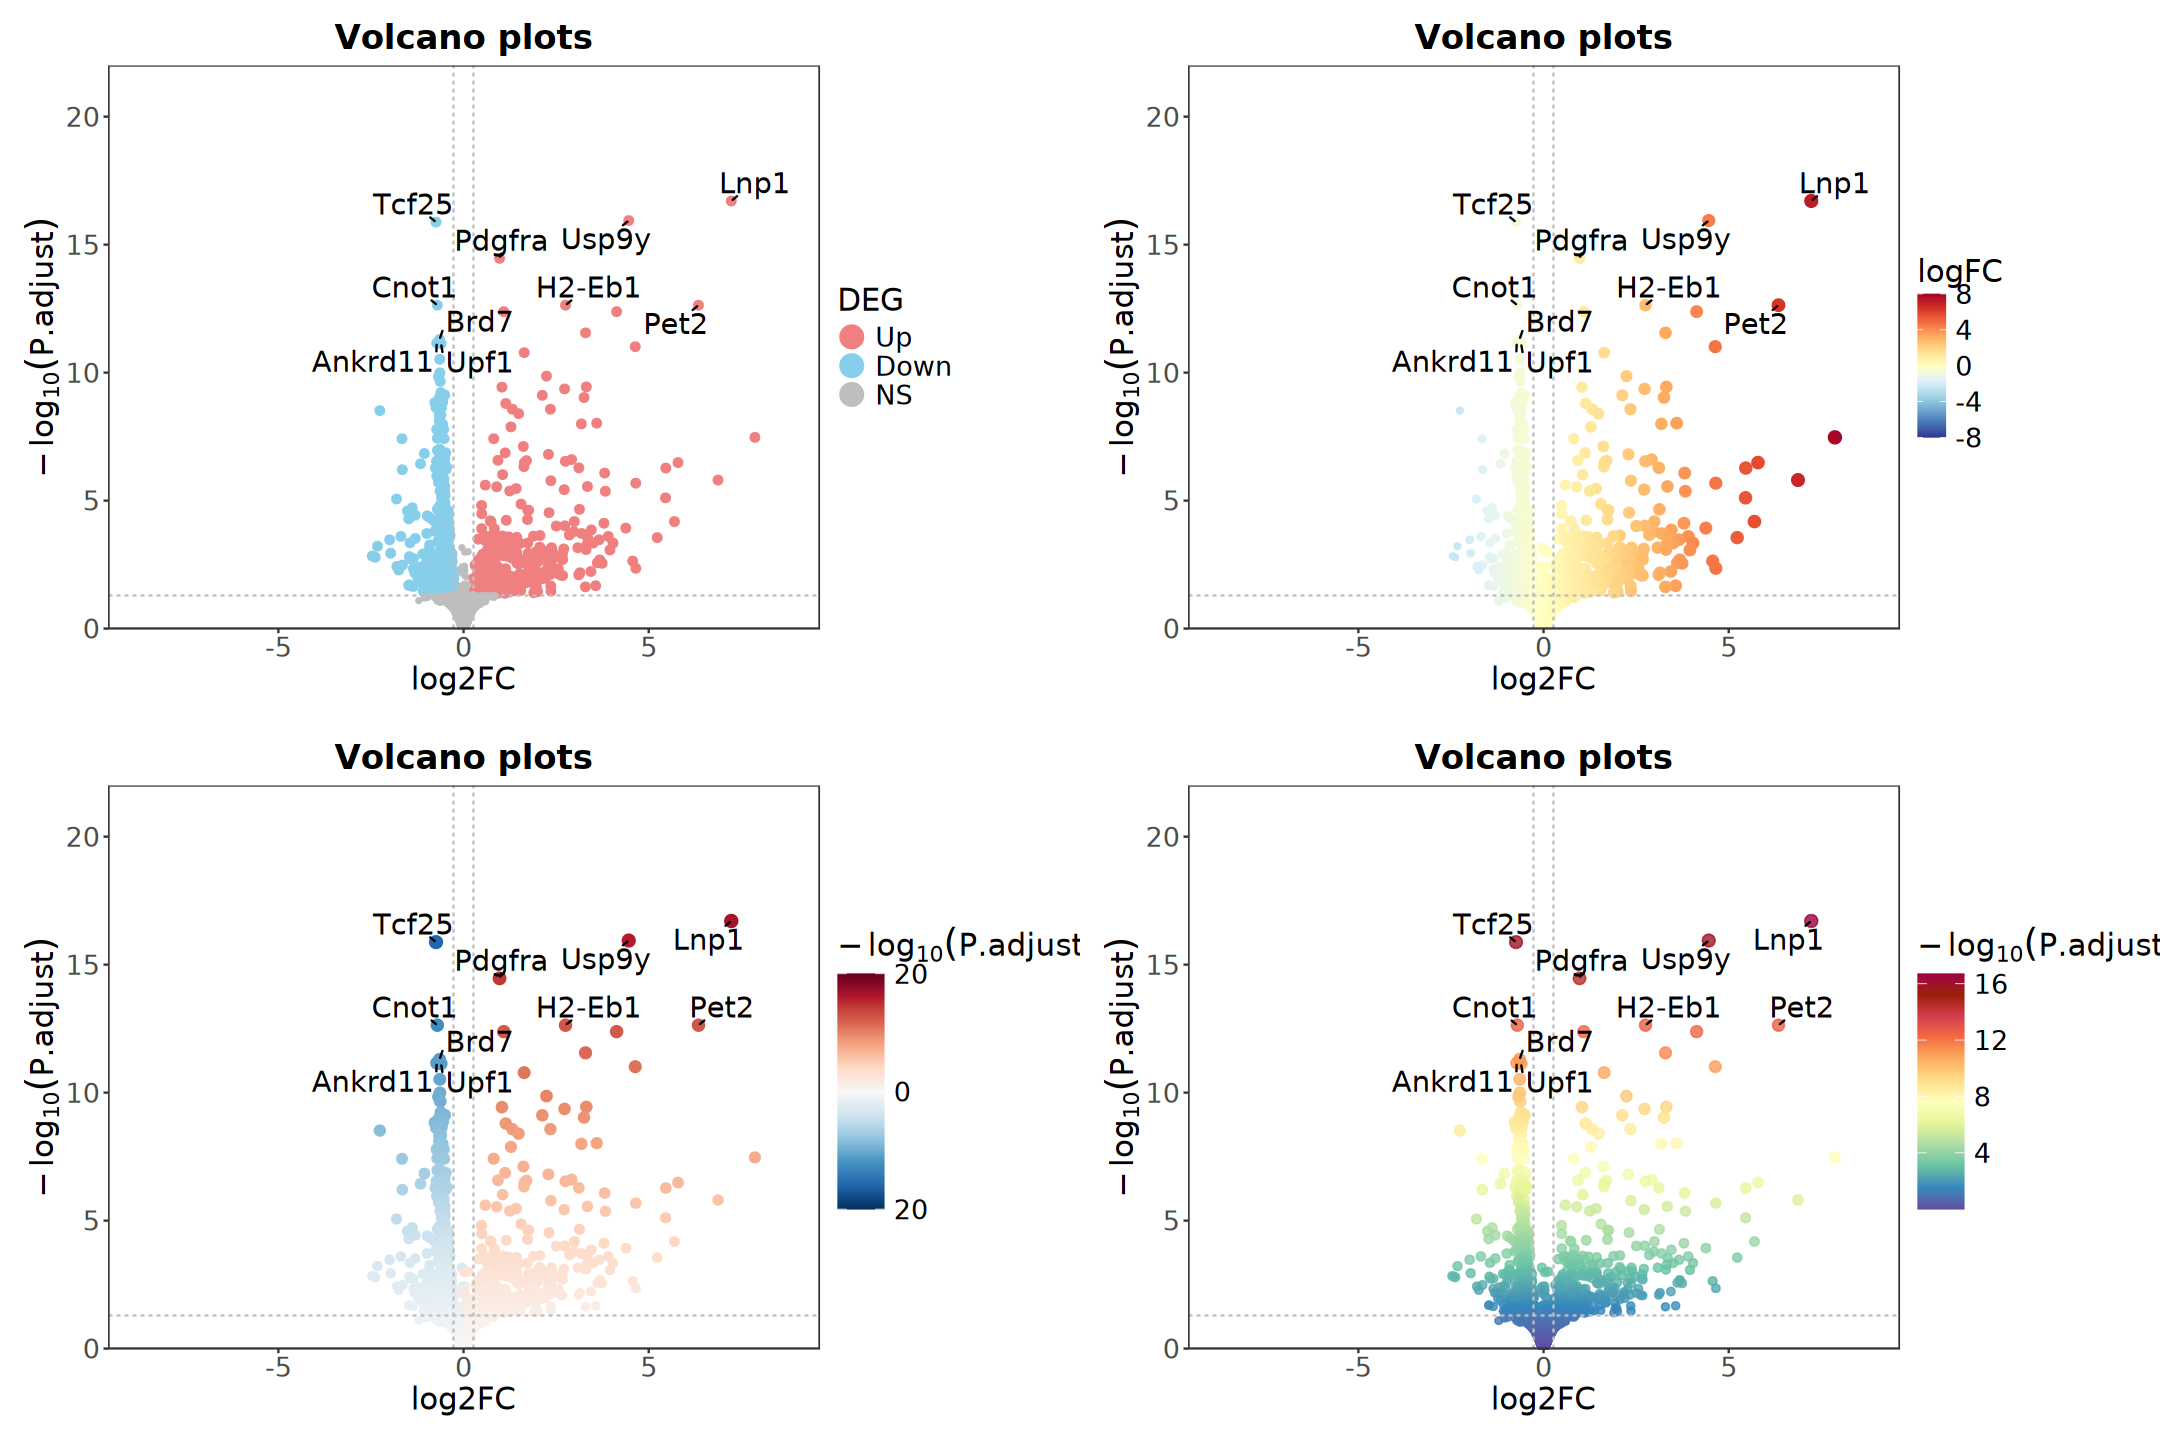

In [138]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [139]:
ctrl_samples <- colnames(dds)[dds$Group == "WT"]
treat_samples <- colnames(dds)[dds$Group == "KO"]

mean_expr <- dds |> 
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [140]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

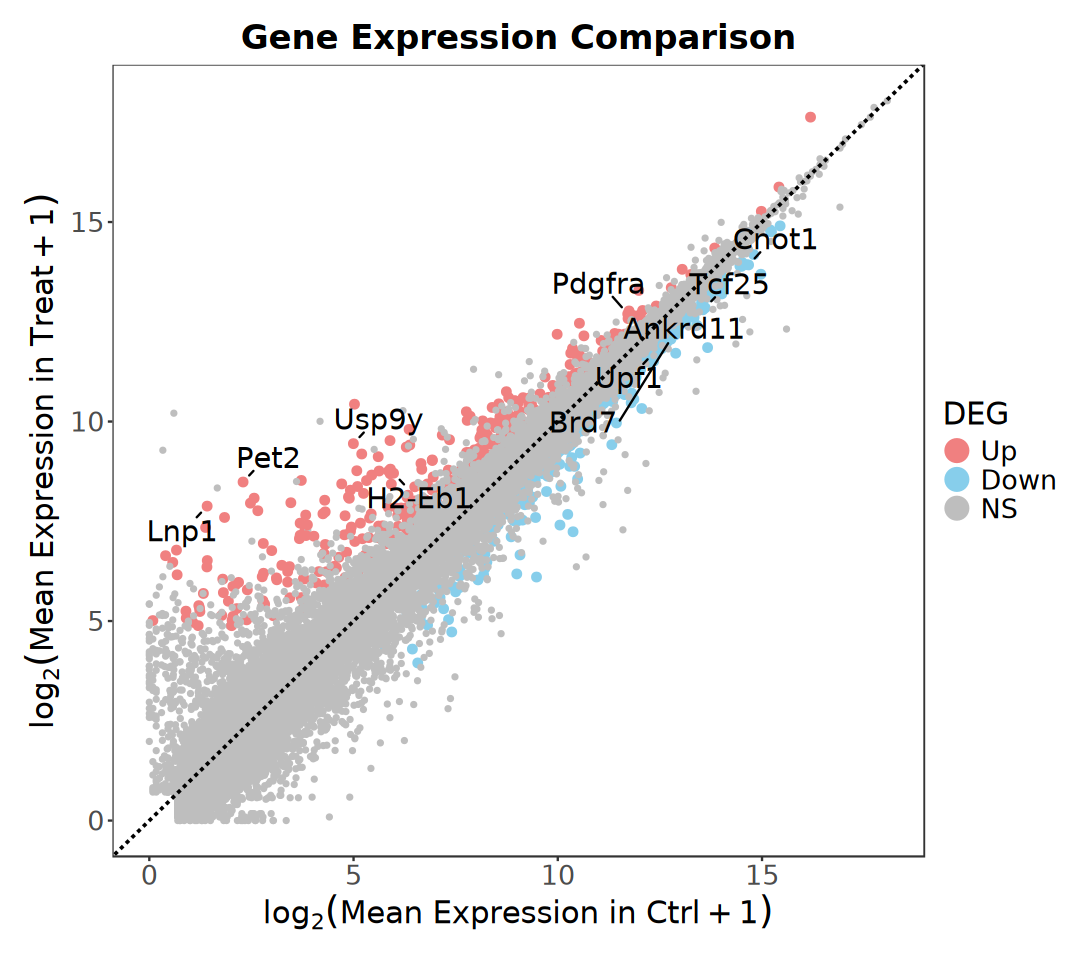

In [141]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [142]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [143]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Status, Group)

In [144]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Status)),
    levels(dds$Status))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Status = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

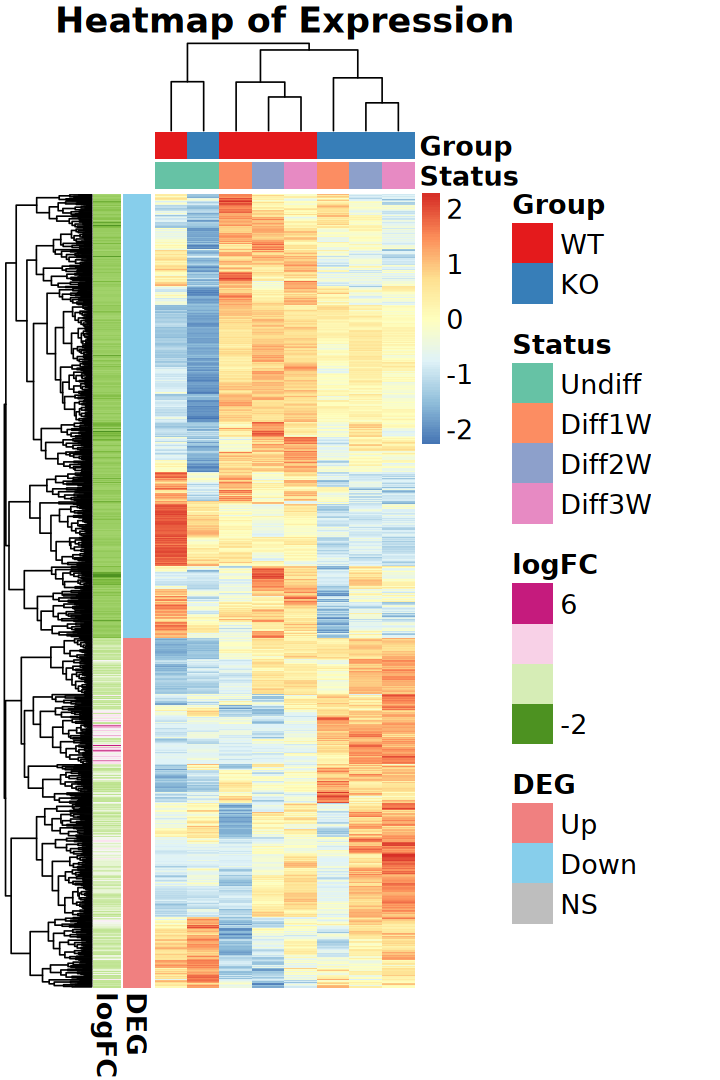

In [145]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [146]:
lr <- degs_result |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    arrange(factor(gene_id, levels = rownames(heatmap_dat))) |>
    pull(label) |>
    replace_na("")

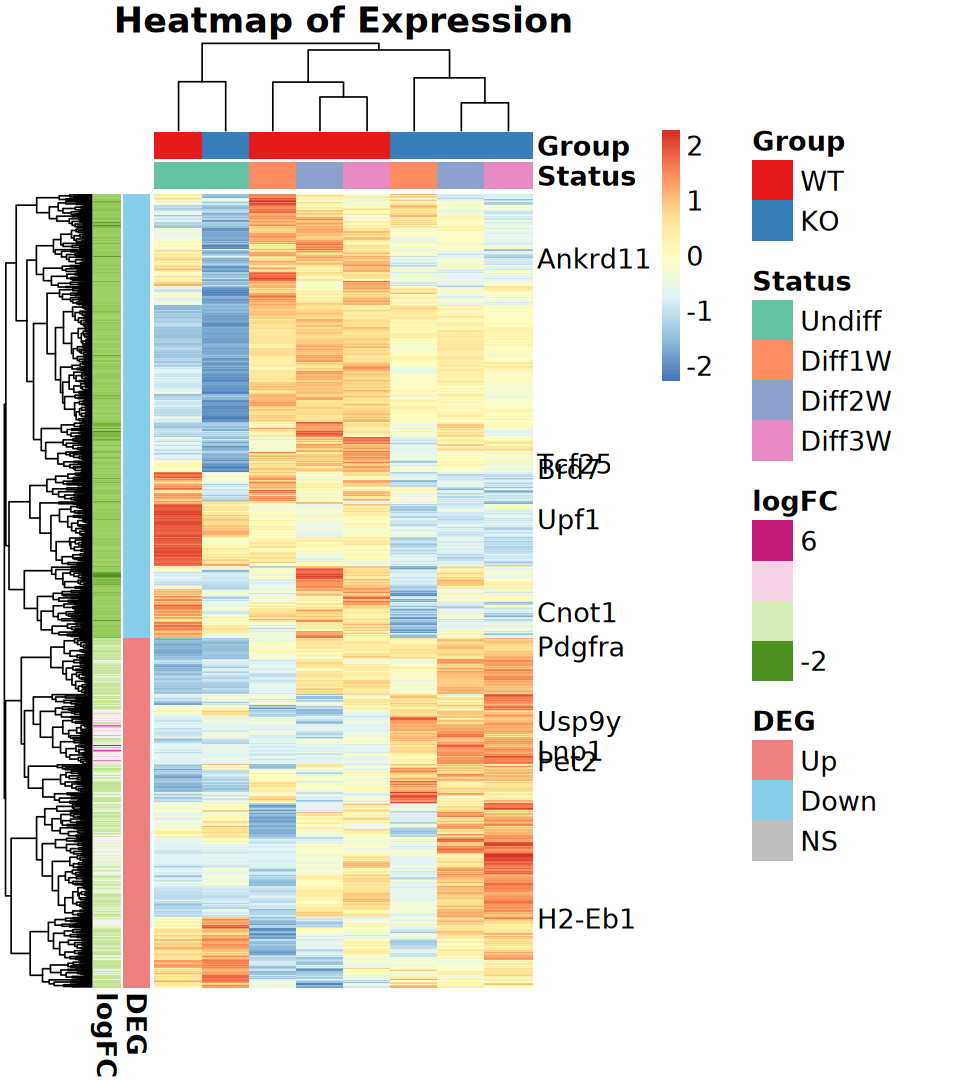

In [147]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, labels_row = lr,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = TRUE)

### ComplexHeatmap

In [148]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [149]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [150]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Status)),
    levels(dds$Status))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [151]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Status)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Status = replicate_colors))

In [152]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [153]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [154]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Status, Group)

In [155]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_replicate <- Legend(
    title = "Status", labels = levels(dds$Status))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [156]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

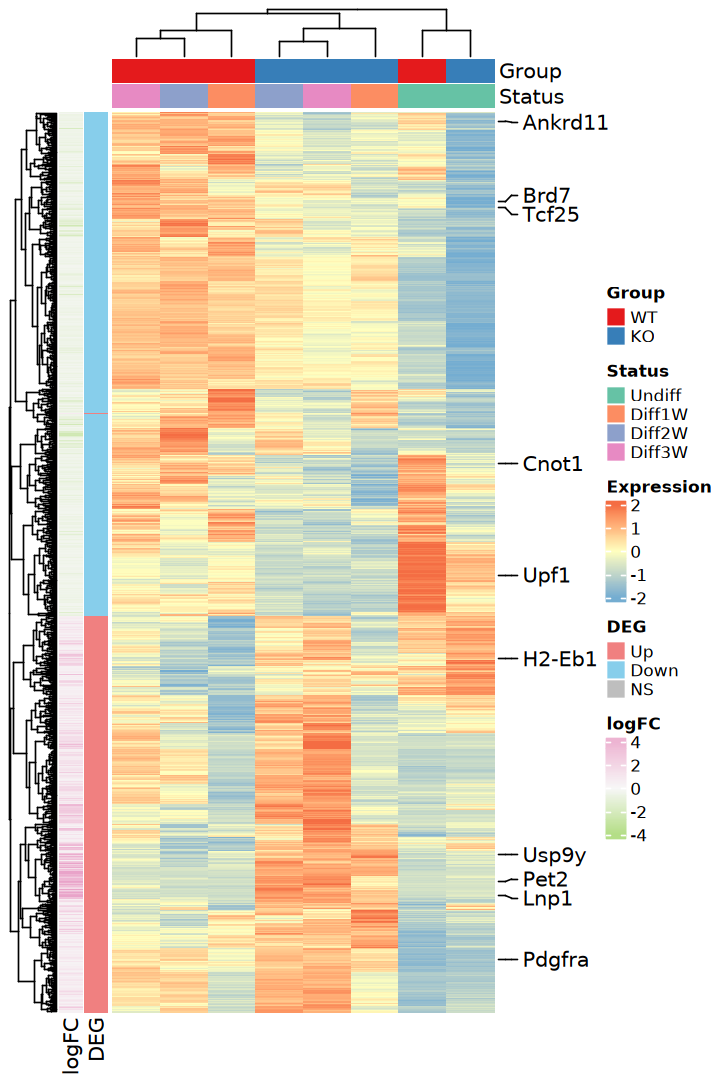

In [157]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [158]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [159]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [160]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
edger_result <- add_ENTREZID(
    edger_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
limma_result <- add_ENTREZID(
    limma_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"20.18% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"10.42% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"10.42% of input gene IDs are fail to map..."


In [161]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [162]:
results_map <- list(
    DESeq2 = deseq2_result, 
    edgeR  = edger_result,
    limma  = limma_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "symbol", result_col = "result")

In [163]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$SYMBOL, edger_result$SYMBOL)), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [164]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0001906,cell killing,25/336,215/17196,0.1162791,5.950997,10.312695,8.303044e-13,2.998229e-09,2.690186e-09,25
2,DESeq2-Up,BP,GO:0035456,response to interferon-beta,12/336,73/17196,0.1643836,8.412916,8.959887,1.608610e-08,2.725817e-05,2.445763e-05,12
3,DESeq2-Up,BP,GO:0019835,cytolysis,6/336,11/17196,0.5454545,27.915584,12.605711,2.264595e-08,2.725817e-05,2.445763e-05,6
4,DESeq2-Up,BP,GO:0035458,cellular response to interferon-beta,11/336,63/17196,0.1746032,8.935941,8.908282,3.348418e-08,3.022784e-05,2.712218e-05,11
5,DESeq2-Up,BP,GO:0031640,killing of cells of another organism,12/336,81/17196,0.1481481,7.582011,8.382134,5.379964e-08,3.237842e-05,2.905181e-05,12
6,DESeq2-Up,BP,GO:0141061,disruption of cell in another organism,12/336,81/17196,0.1481481,7.582011,8.382134,5.379964e-08,3.237842e-05,2.905181e-05,12


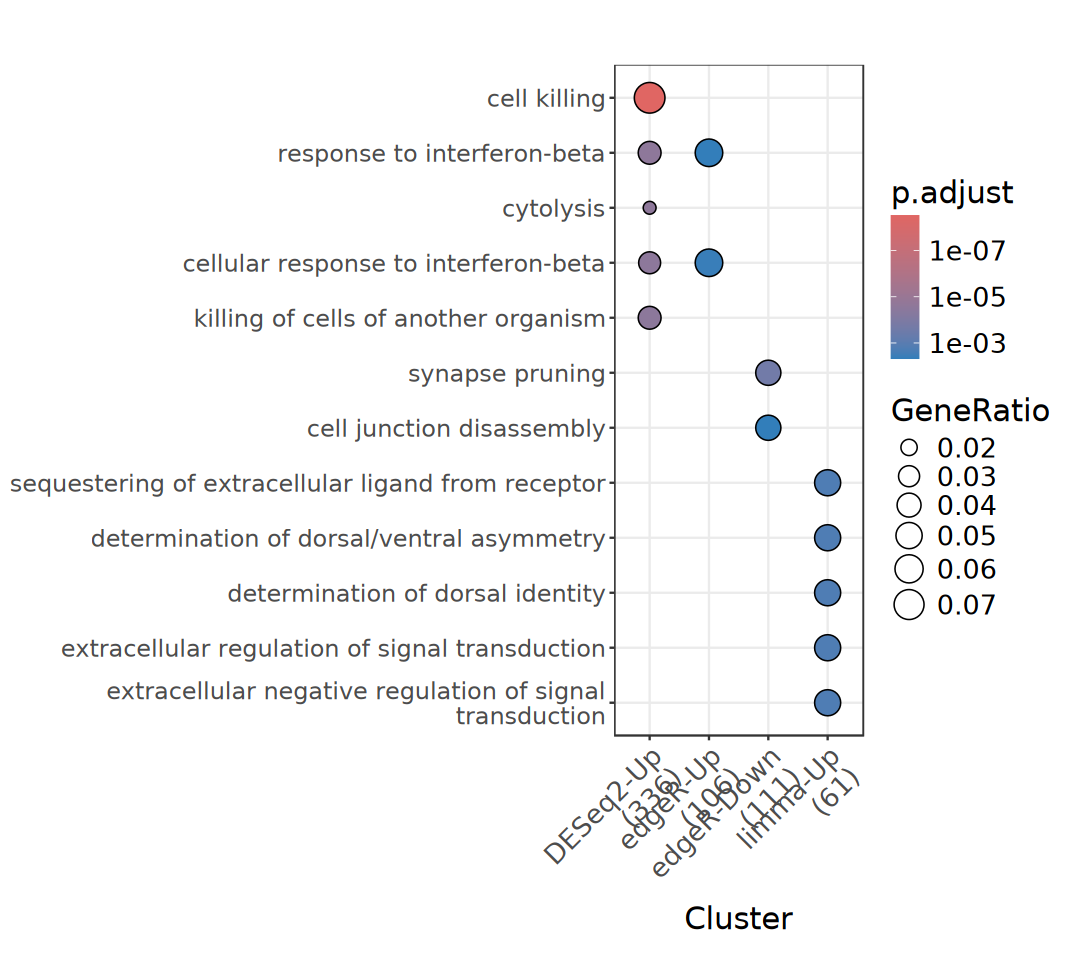

In [165]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [166]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [167]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

Warning message in file(file, "rt"):
"URL 'https://raw.githubusercontent.com/YuLab-SMU/clusterProfiler/refs/heads/gh-pages/md5.txt': Timeout of 60 seconds was reached"


In [168]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,Organismal Systems,Development and regeneration,mmu04382,Cornified envelope formation,14/179,157/7648,0.08917197,3.809985,5.507122,1.677125e-05,0.0040251002,0.0038309068,14
2,edgeR-Up,Human Diseases,Infectious disease: bacterial,mmu05150,Staphylococcus aureus infection,6/49,63/7648,0.09523810,14.864917,8.873095,2.599956e-06,0.0003119947,0.0002490484,6
3,edgeR-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04061,Viral protein interaction with cytokine and cytokine receptor,5/49,67/7648,0.07462687,11.647883,7.029150,6.278198e-05,0.0037669186,0.0030069262,5
4,edgeR-Up,Human Diseases,Immune disease,mmu05323,Rheumatoid arthritis,5/49,77/7648,0.06493506,10.135171,6.469203,1.224227e-04,0.0048969096,0.0039089366,5
5,edgeR-Up,Human Diseases,Infectious disease: viral,mmu05164,Influenza A,6/49,141/7648,0.04255319,6.641772,5.429467,2.570947e-04,0.0077128413,0.0061567417,6
6,limma-Up,Organismal Systems,Development and regeneration,mmu04382,Cornified envelope formation,6/33,157/7648,0.03821656,8.856977,6.547914,4.761262e-05,0.0051897755,0.0049116175,6


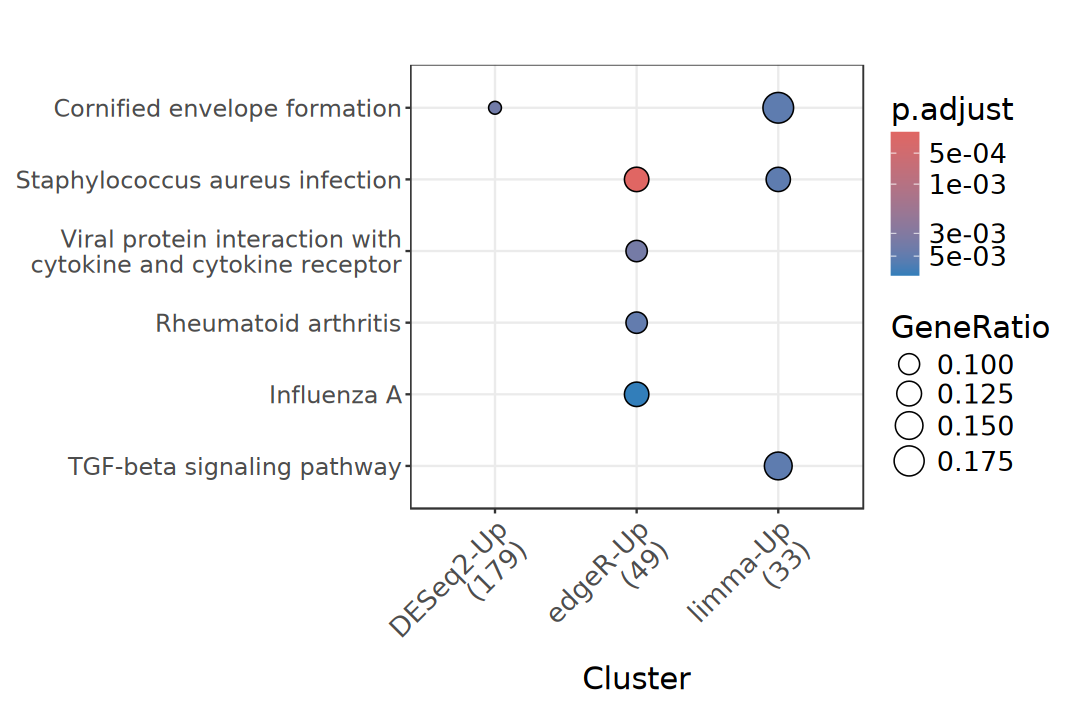

In [169]:
options(repr.plot.width = 9, repr.plot.height = 6)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)